In [1]:
# ============================================================
# OBJECTIVE 2 — REVIEWER 1 VALIDATION
# CELL 1: DATASET AUDIT
# ============================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd

DATA_PATH = Path("./thyroid_cleaned.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH.resolve()}\n"
        "Place this notebook in the same directory as thyroid_cleaned.csv."
    )

df = pd.read_csv(DATA_PATH)

print("=" * 65)
print("DATASET AUDIT")
print("=" * 65)

print("\nDataset path:", DATA_PATH.resolve())
print("Dataset shape:", df.shape)
print("Duplicate rows:", int(df.duplicated().sum()))

# Required columns
required = {"class", "dataset_name", "patient_id"}
missing_required = required - set(df.columns)

if missing_required:
    raise ValueError(f"Required columns missing: {sorted(missing_required)}")

# Target distribution
print("\nTARGET CLASS DISTRIBUTION")
class_counts = df["class"].value_counts(dropna=False).sort_values(
    ascending=False
)
print(class_counts.to_string())

print("\nNumber of target classes:", df["class"].nunique(dropna=True))
print("Missing target values:", int(df["class"].isna().sum()))

# Source-dataset distribution
print("\nSOURCE DATASET DISTRIBUTION")
print(df["dataset_name"].value_counts(dropna=False).to_string())

print("\nUnique source datasets:", df["dataset_name"].nunique(dropna=True))

# Missing values
print("\nMISSING VALUES — TOP 20 COLUMNS")
missing_summary = (
    df.isna()
    .sum()
    .sort_values(ascending=False)
    .head(20)
)
print(missing_summary.to_string())

# Common missing-value markers, counted but not replaced
print("\nCOMMON MISSING-VALUE TOKENS")
for column in df.select_dtypes(include=["object", "string"]).columns:
    values = df[column].astype("string").str.strip()
    count = int(values.isin(["?", "NA", "N/A", "NULL", "null", ""]).sum())
    if count:
        print(f"{column}: {count}")

# Check suspicious age values without modifying the data
if "age" in df.columns:
    print("\nAGE AUDIT")
    print("Age dtype:", df["age"].dtype)
    print("Age == 455:", int((df["age"] == 455).sum()))
    print("Age summary:")
    print(df["age"].describe().to_string())

# Source/target cross-tabulation
print("\nSOURCE DATASET × TARGET CLASS")
source_target = pd.crosstab(
    df["dataset_name"],
    df["class"],
    dropna=False
)
print(source_target.to_string())

# Save audit outputs
OUT_DIR = Path("./REVIEWER1_VALIDATION_RESULTS")
OUT_DIR.mkdir(parents=True, exist_ok=True)

class_counts.rename_axis("class").to_csv(
    OUT_DIR / "audit_class_distribution.csv"
)

df["dataset_name"].value_counts(dropna=False).rename_axis(
    "dataset_name"
).to_csv(OUT_DIR / "audit_source_distribution.csv")

missing_summary.rename_axis("column").to_csv(
    OUT_DIR / "audit_missing_values.csv"
)

source_target.to_csv(
    OUT_DIR / "audit_source_target_crosstab.csv"
)

print("\nAudit files saved to:", OUT_DIR.resolve())
print("CELL 1 COMPLETE — no model trained.")

DATASET AUDIT

Dataset path: /workspace/MB Research Experiments/Objective-2/Refined objective 2/2nd Version/thyroid_cleaned.csv
Dataset shape: (22632, 31)
Duplicate rows: 0

TARGET CLASS DISTRIBUTION
class
negative                     21663
sick                           231
compensated hypothyroid        194
increased binding protein      149
primary hypothyroid             95
hyperthyroid                    79
discordant                      58
underreplacement                52
replacement therapy             38
overreplacement                 34
decreased binding protein       14
goitre                          12
T3 toxic                        10
secondary hypothyroid            2
secondary toxic                  1

Number of target classes: 15
Missing target values: 0

SOURCE DATASET DISTRIBUTION
dataset_name
allrep      3772
dis         3772
sick        3772
allbp       3772
allhyper    3772
allhypo     3772

Unique source datasets: 6

MISSING VALUES — TOP 20 COLUMNS
T3        

In [2]:
# ============================================================
# CELL 2: QUANTIFY SOURCE–TARGET ASSOCIATION
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import normalized_mutual_info_score

audit = df[["dataset_name", "class"]].dropna().copy()

# Source and target proportions
source_counts = pd.crosstab(
    audit["dataset_name"],
    audit["class"]
)

source_proportions = source_counts.div(
    source_counts.sum(axis=1), axis=0
)

# Predict every record using only its source's most frequent class.
source_majority = audit["dataset_name"].map(
    audit.groupby("dataset_name")["class"]
    .agg(lambda s: s.value_counts().idxmax())
)

source_only_accuracy = (source_majority == audit["class"]).mean()

# Dataset-level majority prediction baseline.
overall_majority = audit["class"].value_counts().idxmax()
majority_accuracy = (audit["class"] == overall_majority).mean()

nmi = normalized_mutual_info_score(
    audit["dataset_name"],
    audit["class"]
)

print("=" * 65)
print("SOURCE–TARGET ASSOCIATION AUDIT")
print("=" * 65)

print(f"\nOverall majority-class accuracy: {majority_accuracy:.4%}")
print(f"Source-only majority prediction accuracy: {source_only_accuracy:.4%}")
print(f"Normalized mutual information: {nmi:.4f}")

print("\nTARGET COMPOSITION WITHIN EACH SOURCE (%)")
print((100 * source_proportions).round(2).to_string())

# Save results
OUT_DIR.mkdir(parents=True, exist_ok=True)

source_counts.to_csv(
    OUT_DIR / "source_target_counts.csv"
)
source_proportions.to_csv(
    OUT_DIR / "source_target_proportions.csv"
)

pd.DataFrame([{
    "overall_majority_accuracy": majority_accuracy,
    "source_only_majority_accuracy": source_only_accuracy,
    "source_target_normalized_mutual_information": nmi
}]).to_csv(
    OUT_DIR / "source_target_association_metrics.csv",
    index=False
)

print("\nSaved to:", OUT_DIR.resolve())
print("CELL 2 COMPLETE — no model trained.")

SOURCE–TARGET ASSOCIATION AUDIT

Overall majority-class accuracy: 95.7185%
Source-only majority prediction accuracy: 95.7185%
Normalized mutual information: 0.0747

TARGET COMPOSITION WITHIN EACH SOURCE (%)
class         T3 toxic  compensated hypothyroid  decreased binding protein  discordant  goitre  hyperthyroid  increased binding protein  negative  overreplacement  primary hypothyroid  replacement therapy  secondary hypothyroid  secondary toxic  sick  underreplacement
dataset_name                                                                                                                                                                                                                                                                
allbp             0.00                     0.00                       0.37        0.00    0.00          0.00                       3.95     95.68              0.0                 0.00                 0.00                   0.00             0.00  0.00     

In [3]:
# ============================================================
# CELL 3: PREPARE PAIRED HOLDOUT PARTITIONS (CORRECTED)
# ============================================================

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

TARGET_COL = "class"
TEST_SIZE = 0.20
RANDOM_STATE = 2026

model_df = df.drop(columns=["patient_id"], errors="ignore").copy()
X_all = model_df.drop(columns=[TARGET_COL]).copy()

label_encoder = LabelEncoder()
y_all = label_encoder.fit_transform(model_df[TARGET_COL])
class_names = label_encoder.classes_
n_classes = len(class_names)

class_counts = pd.Series(y_all).value_counts().sort_index()
protected_classes = class_counts[class_counts < 5].index.to_numpy()

protected_mask = np.isin(y_all, protected_classes)
regular_mask = ~protected_mask

X_regular = X_all.loc[regular_mask].reset_index(drop=True)
y_regular = y_all[regular_mask]

X_protected = X_all.loc[protected_mask].reset_index(drop=True)
y_protected = y_all[protected_mask]

X_train_regular, X_test, y_train_regular, y_test = train_test_split(
    X_regular,
    y_regular,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y_regular
)

X_train = pd.concat([X_train_regular, X_protected], ignore_index=True)
y_train = np.concatenate([y_train_regular, y_protected])

assert len(X_test) == 4526
assert len(X_train) + len(X_test) == len(df)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("Features before encoding:", X_train.shape[1])
print("Classes:", n_classes)
print("Protected classes:", [
    (class_names[c], int(class_counts[c])) for c in protected_classes
])
print("Test class distribution:")
print(pd.Series(
    label_encoder.inverse_transform(y_test)
).value_counts().to_string())

print("\nCELL 3 COMPLETE — partitions prepared; no model trained.")

Training rows: 18106
Test rows: 4526
Features before encoding: 29
Classes: 15
Protected classes: [('secondary hypothyroid', 2), ('secondary toxic', 1)]
Test class distribution:
negative                     4333
sick                           46
compensated hypothyroid        39
increased binding protein      30
primary hypothyroid            19
hyperthyroid                   16
discordant                     12
underreplacement               10
overreplacement                 7
replacement therapy             7
decreased binding protein       3
T3 toxic                        2
goitre                          2

CELL 3 COMPLETE — partitions prepared; no model trained.


In [4]:
# ============================================================
# CELL 4: PAIRED SOURCE-INDICATOR ABLATION
# ============================================================

import json
import numpy as np
import pandas as pd

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)
from xgboost import XGBClassifier

OUT_DIR = Path("./REVIEWER1_VALIDATION_RESULTS")
OUT_DIR.mkdir(parents=True, exist_ok=True)

PARAMS = {
    "learning_rate": 0.0343020118,
    "max_depth": 19,
    "subsample": 0.99821606,
    "colsample_bytree": 0.91857801,
    "n_estimators": 879,
    "min_child_weight": 1.0,
    "gamma": 0.49494746,
    "reg_lambda": 0.62217746,
}

conditions = {
    "with_dataset_name": True,
    "without_dataset_name": False,
}

summary_rows = []
prediction_frames = {}
models = {}
preprocessors = {}

for condition, keep_source in conditions.items():
    print(f"\n{'=' * 65}")
    print("Training:", condition)
    print(f"{'=' * 65}")

    Xtr = X_train.copy()
    Xte = X_test.copy()

    if not keep_source:
        Xtr = Xtr.drop(columns=["dataset_name"], errors="ignore")
        Xte = Xte.drop(columns=["dataset_name"], errors="ignore")

    numeric_features = Xtr.select_dtypes(
        include=[np.number]
    ).columns.tolist()

    categorical_features = Xtr.select_dtypes(
        exclude=[np.number]
    ).columns.tolist()

    transformers = []

    if numeric_features:
        numeric_pipeline = Pipeline([
            ("imputer", SimpleImputer(strategy="mean")),
            ("scaler", StandardScaler()),
        ])
        transformers.append(
            ("num", numeric_pipeline, numeric_features)
        )

    if categorical_features:
        categorical_pipeline = Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(
                sparse_output=False,
                handle_unknown="ignore"
            )),
        ])
        transformers.append(
            ("cat", categorical_pipeline, categorical_features)
        )

    preprocessor = ColumnTransformer(
        transformers=transformers,
        remainder="drop"
    )

    Xtr_proc = preprocessor.fit_transform(Xtr)
    Xte_proc = preprocessor.transform(Xte)

    # Preserve original behavior for classes absent from training.
    train_classes = np.unique(y_train)
    missing_classes = sorted(
        set(range(n_classes)) - set(train_classes)
    )

    if missing_classes:
        dummy_X = np.zeros(
            (len(missing_classes), Xtr_proc.shape[1]),
            dtype=Xtr_proc.dtype
        )
        Xtr_proc = np.vstack([Xtr_proc, dummy_X])
        ytr_model = np.concatenate([
            y_train,
            np.asarray(missing_classes, dtype=y_train.dtype)
        ])
    else:
        ytr_model = y_train.copy()

    model = XGBClassifier(
        **PARAMS,
        objective="multi:softprob",
        num_class=n_classes,
        tree_method="hist",
        device="cuda",
        random_state=42,
        eval_metric="mlogloss",
        n_jobs=-1
    )

    model.fit(Xtr_proc, ytr_model)
    y_pred = model.predict(Xte_proc)

    metrics = {
        "condition": condition,
        "processed_features": int(Xtr_proc.shape[1]),
        "accuracy": accuracy_score(y_test, y_pred),
        "macro_precision": precision_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "macro_recall": recall_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "macro_f1": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "weighted_f1": f1_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
    }

    summary_rows.append(metrics)
    prediction_frames[condition] = y_pred
    models[condition] = model
    preprocessors[condition] = preprocessor

    print(pd.Series(metrics).to_string())
    print("\nPredicted class counts:")
    print(pd.Series(
        label_encoder.inverse_transform(y_pred)
    ).value_counts().to_string())

    report = classification_report(
        y_test,
        y_pred,
        labels=np.arange(n_classes),
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )

    pd.DataFrame(report).T.to_csv(
        OUT_DIR / f"{condition}_classification_report.csv"
    )

    cm = confusion_matrix(
        y_test, y_pred, labels=np.arange(n_classes)
    )

    pd.DataFrame(
        cm, index=class_names, columns=class_names
    ).to_csv(OUT_DIR / f"{condition}_confusion_matrix.csv")

    pd.DataFrame({
        "true_class": label_encoder.inverse_transform(y_test),
        "predicted_class": label_encoder.inverse_transform(y_pred)
    }).to_csv(
        OUT_DIR / f"{condition}_predictions.csv",
        index=False
    )

summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(OUT_DIR / "paired_holdout_summary.csv", index=False)

print("\n" + "=" * 65)
print("PAIRED HOLDOUT SUMMARY")
print("=" * 65)
print(summary_df.to_string(index=False))

print("\nSaved results to:", OUT_DIR.resolve())
print("CELL 4 COMPLETE")


Training: with_dataset_name


/opt/conda/lib/python3.11/site-packages/xgboost/core.py:774: UserWarning: [11:06:49] WARNING: /workspace/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


condition             with_dataset_name
processed_features                   38
accuracy                       0.988511
macro_precision                0.821515
macro_recall                   0.719439
macro_f1                       0.741821
weighted_f1                    0.987565
balanced_accuracy              0.719439

Predicted class counts:
negative                     4358
sick                           39
compensated hypothyroid        38
increased binding protein      21
primary hypothyroid            19
underreplacement               14
hyperthyroid                   12
replacement therapy            11
overreplacement                 6
discordant                      5
goitre                          2
decreased binding protein       1

Training: without_dataset_name
condition             without_dataset_name
processed_features                      32
accuracy                          0.957357
macro_precision                   0.073643
macro_recall                      0.076923


In [6]:
import numpy as np
import xgboost as xgb
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score
)

model = models["without_dataset_name"]
preprocessor = preprocessors["without_dataset_name"]

X_test_clinical = X_test.drop(
    columns=["dataset_name"], errors="ignore"
)
X_test_processed = preprocessor.transform(X_test_clinical)

feature_names = list(preprocessor.get_feature_names_out())

# Build a standard DMatrix with matching feature names
dtest = xgb.DMatrix(
    X_test_processed,
    feature_names=feature_names
)

# Predict directly with the fitted booster
booster = model.get_booster()
probabilities = booster.predict(dtest)
y_pred_gpu = np.argmax(probabilities, axis=1)

print("XGBoost version:", xgb.__version__)
print("Configured model device:", model.get_xgb_params().get("device"))
print("\n--- Source-free holdout results ---")
print(f"Accuracy:          {accuracy_score(y_test, y_pred_gpu):.6f}")
print(f"Macro precision:   {precision_score(y_test, y_pred_gpu, average='macro', zero_division=0):.6f}")
print(f"Macro recall:      {recall_score(y_test, y_pred_gpu, average='macro', zero_division=0):.6f}")
print(f"Macro F1:          {f1_score(y_test, y_pred_gpu, average='macro', zero_division=0):.6f}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_test, y_pred_gpu):.6f}")

# Compare against the previous run
y_pred_previous = prediction_frames[
    "without_dataset_name"
]["prediction"].to_numpy()

print("\nPredictions identical to previous run:",
      np.array_equal(y_pred_previous, y_pred_gpu))
print("Differing predictions:",
      np.count_nonzero(y_pred_previous != y_pred_gpu))

XGBoost version: 3.1.1
Configured model device: cuda

--- Source-free holdout results ---
Accuracy:          0.957357
Macro precision:   0.073643
Macro recall:      0.076923
Macro F1:          0.075247
Balanced accuracy: 0.076923


IndexError: only integers, slices (`:`), ellipsis (`...`), numpy.newaxis (`None`) and integer or boolean arrays are valid indices

In [7]:
previous = prediction_frames["without_dataset_name"]

if isinstance(previous, pd.DataFrame):
    y_pred_previous = previous["prediction"].to_numpy()
elif isinstance(previous, pd.Series):
    y_pred_previous = previous.to_numpy()
else:
    y_pred_previous = np.asarray(previous)

# If the stored predictions are class probabilities, convert to class labels
if y_pred_previous.ndim == 2:
    y_pred_previous = np.argmax(y_pred_previous, axis=1)

print("Predictions identical to previous run:",
      np.array_equal(y_pred_previous, y_pred_gpu))

print("Differing predictions:",
      np.count_nonzero(y_pred_previous != y_pred_gpu))

Predictions identical to previous run: True
Differing predictions: 0


In [8]:
# ============================================================
# CELL 5: CLINICAL-ONLY SHAP ANALYSIS
# ============================================================

import xgboost as xgb
import numpy as np
import pandas as pd

OUT_DIR = Path("./REVIEWER1_VALIDATION_RESULTS")

# Retrieve the source-free model and its fitted preprocessor.
model = models["without_dataset_name"]
preprocessor = preprocessors["without_dataset_name"]

X_test_clinical = X_test.drop(
    columns=["dataset_name"], errors="ignore"
)

X_test_processed = preprocessor.transform(X_test_clinical)

feature_names = preprocessor.get_feature_names_out()

# Use a DMatrix for native XGBoost contributions.
dtest = xgb.DMatrix(
    X_test_processed,
    feature_names=list(feature_names)
)

print("Calculating native XGBoost SHAP contributions...")
print("Holdout records:", X_test_processed.shape[0])
print("Processed features:", len(feature_names))

contribs = model.get_booster().predict(
    dtest,
    pred_contribs=True
)

if contribs.ndim != 3:
    raise RuntimeError(
        f"Unexpected contribution shape: {contribs.shape}"
    )

# The last column is the bias term.
feature_contribs = contribs[:, :, :-1]

# Overall mean absolute contribution, averaged across class outputs.
mean_abs_shap = np.mean(
    np.abs(feature_contribs),
    axis=(0, 1)
)

shap_global = (
    pd.DataFrame({
        "feature": feature_names,
        "mean_absolute_shap": mean_abs_shap
    })
    .sort_values("mean_absolute_shap", ascending=False)
)

shap_global.to_csv(
    OUT_DIR / "clinical_only_shap_global_importance.csv",
    index=False
)

print("\nTOP 20 CLINICAL-ONLY SHAP FEATURES")
print(shap_global.head(20).to_string(index=False))

# Save raw contributions and corresponding feature names.
np.save(
    OUT_DIR / "clinical_only_shap_contributions.npy",
    contribs
)

pd.Series(feature_names, name="feature").to_csv(
    OUT_DIR / "clinical_only_shap_feature_names.csv",
    index=False
)

print("\nSHAP results saved to:", OUT_DIR.resolve())
print("CELL 5 COMPLETE")

Calculating native XGBoost SHAP contributions...
Holdout records: 4526
Processed features: 32

TOP 20 CLINICAL-ONLY SHAP FEATURES
                       feature  mean_absolute_shap
                      num__TSH            0.570773
                      num__FTI            0.426691
             num__on thyroxine            0.351807
                       num__T3            0.351500
                      num__T4U            0.266645
                      num__TT4            0.235641
                    num__tumor            0.103748
                      num__age            0.047073
             num__TSH measured            0.014001
num__on antithyroid medication            0.012809
    cat__referral source_other            0.010497
             num__FTI measured            0.009783
      cat__referral source_SVI            0.009578
             num__T4U measured            0.009520
                      num__sex            0.008867
          num__thyroid surgery            0.008491
   

In [9]:
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score
)
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from xgboost import XGBClassifier
import numpy as np
import pandas as pd
from pathlib import Path

OUT_DIR = Path("./REVIEWER1_VALIDATION_RESULTS")
OUT_DIR.mkdir(exist_ok=True)

# Match the original fixed EvoX-Boost hyperparameters
MODEL_PARAMS = {
    "learning_rate": 0.0343020118,
    "max_depth": 19,
    "n_estimators": 879,
    "subsample": 0.99821606,
    "colsample_bytree": 0.91857801,
    "min_child_weight": 1,
    "gamma": 0.49494746,
    "reg_lambda": 0.62217746,
    "objective": "multi:softprob",
    "num_class": n_classes,
    "tree_method": "hist",
    "device": "cuda",
    "eval_metric": "mlogloss",
    "n_jobs": -1,
    "random_state": 42,
}

def make_preprocessor(X):
    numeric_cols = X.select_dtypes(include=["number", "bool"]).columns.tolist()
    categorical_cols = X.select_dtypes(exclude=["number", "bool"]).columns.tolist()

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="mean")),
        ("scaler", StandardScaler()),
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )),
    ])

    return ColumnTransformer([
        ("num", numeric_pipeline, numeric_cols),
        ("cat", categorical_pipeline, categorical_cols),
    ])

# Use the same folds for both conditions
X_all = X_train.copy()
y_all = np.asarray(y_train)

# The two ultra-rare classes were protected in the original split.
# Keep this CV on the original training partition and report its class coverage.
cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=5,
    random_state=2026
)
splits = list(cv.split(X_all, y_all))

conditions = {
    "with_dataset_name": X_all,
    "without_dataset_name": X_all.drop(
        columns=["dataset_name"], errors="ignore"
    ),
}

all_rows = []

for condition, X_condition in conditions.items():
    print(f"\nRunning CV: {condition}")
    for fold_idx, (train_idx, val_idx) in enumerate(splits, start=1):
        X_fold_train = X_condition.iloc[train_idx]
        X_fold_val = X_condition.iloc[val_idx]
        y_fold_train = y_all[train_idx]
        y_fold_val = y_all[val_idx]

        prep = make_preprocessor(X_fold_train)
        X_fold_train_processed = prep.fit_transform(X_fold_train)
        X_fold_val_processed = prep.transform(X_fold_val)

        # Keep all target classes represented for multiclass output.
        # Add a zero-weight synthetic row for any absent training class.
        present = set(np.unique(y_fold_train))
        missing_classes = [c for c in range(n_classes) if c not in present]

        if missing_classes:
            X_fold_train_processed = np.vstack([
                X_fold_train_processed,
                np.zeros((len(missing_classes), X_fold_train_processed.shape[1]))
            ])
            y_fold_train = np.concatenate([
                y_fold_train,
                np.array(missing_classes)
            ])
            sample_weight = np.concatenate([
                np.ones(len(train_idx)),
                np.zeros(len(missing_classes))
            ])
        else:
            sample_weight = None

        model = XGBClassifier(**MODEL_PARAMS)
        model.fit(
            X_fold_train_processed,
            y_fold_train,
            sample_weight=sample_weight
        )

        y_pred = model.predict(X_fold_val_processed)

        all_rows.append({
            "condition": condition,
            "fold": fold_idx,
            "accuracy": accuracy_score(y_val := y_all[val_idx], y_pred),
            "macro_precision": precision_score(y_val, y_pred, average="macro", zero_division=0),
            "macro_recall": recall_score(y_val, y_pred, average="macro", zero_division=0),
            "macro_f1": f1_score(y_val, y_pred, average="macro", zero_division=0),
            "weighted_f1": f1_score(y_val, y_pred, average="weighted", zero_division=0),
            "balanced_accuracy": balanced_accuracy_score(y_val, y_pred),
            "features": X_fold_train_processed.shape[1],
        })

        if fold_idx % 5 == 0:
            print(f"  Completed {fold_idx}/{len(splits)} folds")

cv_results = pd.DataFrame(all_rows)
cv_results.to_csv(OUT_DIR / "paired_cv_ablation_corrected.csv", index=False)

summary = cv_results.groupby("condition").agg(
    accuracy_mean=("accuracy", "mean"),
    accuracy_sd=("accuracy", "std"),
    macro_precision_mean=("macro_precision", "mean"),
    macro_recall_mean=("macro_recall", "mean"),
    macro_f1_mean=("macro_f1", "mean"),
    macro_f1_sd=("macro_f1", "std"),
    weighted_f1_mean=("weighted_f1", "mean"),
    balanced_accuracy_mean=("balanced_accuracy", "mean"),
).round(6)

print("\n--- Repeated stratified 5-fold CV (5 repeats) ---")
print(summary)
summary.to_csv(OUT_DIR / "paired_cv_ablation_corrected_summary.csv")
print("\nSaved corrected CV results.")

/opt/conda/lib/python3.11/site-packages/sklearn/model_selection/_split.py:811: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(
/opt/conda/lib/python3.11/site-packages/sklearn/model_selection/_split.py:811: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(
/opt/conda/lib/python3.11/site-packages/sklearn/model_selection/_split.py:811: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(
/opt/conda/lib/python3.11/site-packages/sklearn/model_selection/_split.py:811: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(
/opt/conda/lib/python3.11/site-packages/sklearn/model_selection/_split.py:811: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(



Running CV: with_dataset_name
  Completed 5/25 folds
  Completed 10/25 folds
  Completed 15/25 folds
  Completed 20/25 folds
  Completed 25/25 folds

Running CV: without_dataset_name
  Completed 5/25 folds
  Completed 10/25 folds
  Completed 15/25 folds
  Completed 20/25 folds
  Completed 25/25 folds

--- Repeated stratified 5-fold CV (5 repeats) ---
                      accuracy_mean  accuracy_sd  macro_precision_mean  \
condition                                                                
with_dataset_name          0.988037     0.001510              0.724519   
without_dataset_name       0.957053     0.000307              0.070471   

                      macro_recall_mean  macro_f1_mean  macro_f1_sd  \
condition                                                             
with_dataset_name              0.646561       0.669581     0.057637   
without_dataset_name           0.073620       0.072011     0.002692   

                      weighted_f1_mean  balanced_accuracy_mean  

In [10]:
import pandas as pd
from pathlib import Path

OUT_DIR = Path("./REVIEWER1_VALIDATION_RESULTS")

results = pd.read_csv(
    OUT_DIR / "paired_cv_ablation_corrected.csv"
)

print("Fold-level results:", results.shape)

print("\nPrediction metrics by condition:")
print(
    results.groupby("condition")[
        ["accuracy", "macro_f1", "balanced_accuracy"]
    ].agg(["mean", "std"]).round(6)
)

print("\nFeature counts by condition:")
print(results.groupby("condition")["features"].agg(["min", "max"]).to_string())

print("\nSaved CV file:", (OUT_DIR / "paired_cv_ablation_corrected.csv").exists())

Fold-level results: (50, 9)

Prediction metrics by condition:
                      accuracy            macro_f1            \
                          mean       std      mean       std   
condition                                                      
with_dataset_name     0.988037  0.001510  0.669581  0.057637   
without_dataset_name  0.957053  0.000307  0.072011  0.002692   

                     balanced_accuracy            
                                  mean       std  
condition                                         
with_dataset_name             0.646561  0.052374  
without_dataset_name          0.073620  0.002753  

Feature counts by condition:
                      min  max
condition                     
with_dataset_name      38   38
without_dataset_name   32   32

Saved CV file: True


In [11]:
from pathlib import Path

out_dir = Path("./REVIEWER1_VALIDATION_RESULTS")

files_to_check = [
    "with_dataset_name_classification_report.csv",
    "without_dataset_name_classification_report.csv",
    "with_dataset_name_predictions.csv",
    "without_dataset_name_predictions.csv",
    "paired_cv_ablation_corrected.csv",
]

for filename in files_to_check:
    path = out_dir / filename
    print(f"{filename}: {'FOUND' if path.exists() else 'NOT FOUND'}")

with_dataset_name_classification_report.csv: FOUND
without_dataset_name_classification_report.csv: FOUND
with_dataset_name_predictions.csv: FOUND
without_dataset_name_predictions.csv: FOUND
paired_cv_ablation_corrected.csv: FOUND


In [12]:
import pandas as pd
from pathlib import Path

out_dir = Path("./REVIEWER1_VALIDATION_RESULTS")

# 1. Compare per-class holdout metrics
with_source = pd.read_csv(
    out_dir / "with_dataset_name_classification_report.csv"
)
without_source = pd.read_csv(
    out_dir / "without_dataset_name_classification_report.csv"
)

print("=== WITH DATASET SOURCE INDICATOR ===")
print(with_source.to_string(index=False))

print("\n=== WITHOUT DATASET SOURCE INDICATOR ===")
print(without_source.to_string(index=False))

# 2. Inspect predicted class distributions
pred_with = pd.read_csv(
    out_dir / "with_dataset_name_predictions.csv"
)
pred_without = pd.read_csv(
    out_dir / "without_dataset_name_predictions.csv"
)

print("\n=== PREDICTION FILE COLUMNS ===")
print("With source:", pred_with.columns.tolist())
print("Without source:", pred_without.columns.tolist())

print("\n=== PREDICTED CLASS COUNTS: WITH SOURCE ===")
print(pred_with["prediction"].value_counts().to_string())

print("\n=== PREDICTED CLASS COUNTS: WITHOUT SOURCE ===")
print(pred_without["prediction"].value_counts().to_string())

=== WITH DATASET SOURCE INDICATOR ===
               Unnamed: 0  precision   recall  f1-score     support
                 T3 toxic   0.000000 0.000000  0.000000    2.000000
  compensated hypothyroid   0.973684 0.948718  0.961039   39.000000
decreased binding protein   1.000000 0.333333  0.500000    3.000000
               discordant   0.800000 0.333333  0.470588   12.000000
                   goitre   1.000000 1.000000  1.000000    2.000000
             hyperthyroid   0.916667 0.687500  0.785714   16.000000
increased binding protein   0.904762 0.633333  0.745098   30.000000
                 negative   0.991510 0.997231  0.994362 4333.000000
          overreplacement   0.833333 0.714286  0.769231    7.000000
      primary hypothyroid   1.000000 1.000000  1.000000   19.000000
      replacement therapy   0.545455 0.857143  0.666667    7.000000
    secondary hypothyroid   0.000000 0.000000  0.000000    0.000000
          secondary toxic   0.000000 0.000000  0.000000    0.000000
          

KeyError: 'prediction'

In [13]:
print("=== PREDICTED CLASS COUNTS: WITH SOURCE ===")
print(
    pred_with["predicted_class"]
    .value_counts()
    .to_string()
)

print("\n=== PREDICTED CLASS COUNTS: WITHOUT SOURCE ===")
print(
    pred_without["predicted_class"]
    .value_counts()
    .to_string()
)

# Confirm the number of unique predicted classes
print("\nUnique classes predicted with source:",
      pred_with["predicted_class"].nunique())

print("Unique classes predicted without source:",
      pred_without["predicted_class"].nunique())

# Verify whether the source-free model predicts only the negative class
print("Source-free predictions all negative:",
      pred_without["predicted_class"].eq("negative").all())

=== PREDICTED CLASS COUNTS: WITH SOURCE ===
predicted_class
negative                     4358
sick                           39
compensated hypothyroid        38
increased binding protein      21
primary hypothyroid            19
underreplacement               14
hyperthyroid                   12
replacement therapy            11
overreplacement                 6
discordant                      5
goitre                          2
decreased binding protein       1

=== PREDICTED CLASS COUNTS: WITHOUT SOURCE ===
predicted_class
negative    4526

Unique classes predicted with source: 12
Unique classes predicted without source: 1
Source-free predictions all negative: True


In [14]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score
)

labels = np.arange(n_classes)

for name, pred_df in [
    ("With dataset_name", pred_with),
    ("Without dataset_name", pred_without),
]:
    y_true_labels = label_encoder.transform(
        pred_df["true_class"].to_numpy()
    )
    y_pred_labels = label_encoder.transform(
        pred_df["predicted_class"].to_numpy()
    )

    print(f"\n=== {name} ===")
    print(f"Accuracy:          {accuracy_score(y_true_labels, y_pred_labels):.6f}")
    print(f"Macro precision:   {precision_score(y_true_labels, y_pred_labels, labels=labels, average='macro', zero_division=0):.6f}")
    print(f"Macro recall:      {recall_score(y_true_labels, y_pred_labels, labels=labels, average='macro', zero_division=0):.6f}")
    print(f"Macro F1:          {f1_score(y_true_labels, y_pred_labels, labels=labels, average='macro', zero_division=0):.6f}")
    print(f"Weighted F1:       {f1_score(y_true_labels, y_pred_labels, labels=labels, average='weighted', zero_division=0):.6f}")
    print(f"Balanced accuracy: {balanced_accuracy_score(y_true_labels, y_pred_labels):.6f}")


=== With dataset_name ===
Accuracy:          0.988511
Macro precision:   0.711980
Macro recall:      0.623514
Macro F1:          0.642912
Weighted F1:       0.987565
Balanced accuracy: 0.719439

=== Without dataset_name ===
Accuracy:          0.957357
Macro precision:   0.063824
Macro recall:      0.066667
Macro F1:          0.065214
Weighted F1:       0.936501
Balanced accuracy: 0.076923


In [15]:
from pathlib import Path
import pandas as pd

# Use the existing notebook dataset if available.
print("=== DATASET COLUMNS ===")
print(df.columns.tolist() if "df" in globals()
      else X_train.columns.tolist())

print("\n=== CANDIDATE TREATMENT / MEASUREMENT FEATURES ===")
columns = df.columns.tolist() if "df" in globals() else X_train.columns.tolist()

for col in columns:
    if any(term in col.lower() for term in [
        "thyroxine", "antithyroid", "surgery", "iodine",
        "treatment", "measured", "tbg", "pregnant"
    ]):
        print(col)

# Inspect existing sensitivity-analysis outputs without overwriting them.
out_dir = Path("./REVIEWER1_VALIDATION_RESULTS")

print("\n=== EXISTING SENSITIVITY FILES ===")
if out_dir.exists():
    matches = sorted(
        p.name for p in out_dir.iterdir()
        if any(term in p.name.lower() for term in [
            "sensitiv", "treatment", "measurement", "ablation"
        ])
    )
    print("\n".join(matches) if matches else "No matching output filenames found.")
else:
    print("Output directory not found.")

=== DATASET COLUMNS ===
['patient_id', 'age', 'sex', 'on thyroxine', 'query on thyroxine', 'on antithyroid medication', 'sick', 'pregnant', 'thyroid surgery', 'I131 treatment', 'query hypothyroid', 'query hyperthyroid', 'lithium', 'goitre', 'tumor', 'hypopituitary', 'psych', 'TSH measured', 'TSH', 'T3 measured', 'T3', 'TT4 measured', 'TT4', 'T4U measured', 'T4U', 'FTI measured', 'FTI', 'TBG measured', 'referral source', 'class', 'dataset_name']

=== CANDIDATE TREATMENT / MEASUREMENT FEATURES ===
on thyroxine
query on thyroxine
on antithyroid medication
pregnant
thyroid surgery
I131 treatment
TSH measured
T3 measured
TT4 measured
T4U measured
FTI measured
TBG measured

=== EXISTING SENSITIVITY FILES ===
paired_cv_ablation_corrected.csv
paired_cv_ablation_corrected_summary.csv


In [16]:
from pathlib import Path

root = Path(
    "/workspace/MB Research Experiments/Objective-2/"
    "Refined objective 2/2nd Version"
)

print("Candidate scripts and notebooks:")
for path in sorted(root.rglob("*")):
    if path.is_file() and path.suffix.lower() in {
        ".py", ".ipynb"
    }:
        name = path.name.lower()
        if any(term in name for term in [
            "sensitiv", "ablation", "objective", "3z", "reviewer"
        ]):
            print(path)

Candidate scripts and notebooks:
/workspace/MB Research Experiments/Objective-2/Refined objective 2/2nd Version/.ipynb_checkpoints/3Z-E2-checkpoint.py
/workspace/MB Research Experiments/Objective-2/Refined objective 2/2nd Version/.ipynb_checkpoints/paired_ablation-checkpoint.py
/workspace/MB Research Experiments/Objective-2/Refined objective 2/2nd Version/.ipynb_checkpoints/paired_cv_ablation-checkpoint.py
/workspace/MB Research Experiments/Objective-2/Refined objective 2/2nd Version/3Z-E2.py
/workspace/MB Research Experiments/Objective-2/Refined objective 2/2nd Version/paired_ablation.py
/workspace/MB Research Experiments/Objective-2/Refined objective 2/2nd Version/paired_cv_ablation.py


In [17]:
from pathlib import Path

root = Path(
    "/workspace/MB Research Experiments/Objective-2/"
    "Refined objective 2/2nd Version"
)

terms = [
    "treatment", "measurement", "measured",
    "drop(columns", "drop(", "macro_f1",
    "macro-f1", "feature_groups", "sensitivity"
]

for filename in ["3Z-E2.py", "paired_ablation.py",
                 "paired_cv_ablation.py"]:
    path = root / filename
    print(f"\n{'=' * 25}\nFILE: {filename}\n{'=' * 25}")

    if not path.exists():
        print("File not found")
        continue

    lines = path.read_text(errors="replace").splitlines()
    matches = [
        i for i, line in enumerate(lines)
        if any(term in line.lower() for term in terms)
    ]

    shown = set()
    for i in matches:
        start, end = max(0, i - 3), min(len(lines), i + 4)
        if any(j in shown for j in range(start, end)):
            continue
        print(f"\n--- Lines {start + 1}-{end} ---")
        for j in range(start, end):
            print(f"{j + 1:4}: {lines[j]}")
            shown.add(j)


FILE: 3Z-E2.py

--- Lines 10-16 ---
  10: # IMPORTANT:
  11: # - Historical feature definition retained
  12: # - dataset_name retained
  13: # - TBG measured retained
  14: # - Published EvoX-Boost parameters fixed
  15: # - No hyperparameter optimization
  16: # - No test-set tuning

--- Lines 78-84 ---
  78: # IMPORTANT:
  79: # Historical Objective-1 removed ONLY patient_id.
  80: # dataset_name remains intentionally.
  81: # TBG measured remains intentionally.
  82: # ============================================================
  83: 
  84: df = df.drop(

--- Lines 101-107 ---
 101: # 4. SPLIT FEATURES / TARGET
 102: # ============================================================
 103: 
 104: X = df.drop(
 105:     columns=[TARGET_COL]
 106: ).copy()
 107: 

--- Lines 638-644 ---
 638:     zero_division=0
 639: )
 640: 
 641: macro_f1 = f1_score(
 642:     y_test,
 643:     y_pred,
 644:     average="macro",

--- Lines 679-685 ---
 679: )
 680: 
 681: print(
 682:     f"Macro F1  

In [18]:
# Proposed feature groups for sensitivity analysis

treatment_features = [
    "on thyroxine",
    "query on thyroxine",
    "on antithyroid medication",
    "thyroid surgery",
    "I131 treatment",
]

measurement_indicator_features = [
    "TSH measured",
    "T3 measured",
    "TT4 measured",
    "T4U measured",
    "FTI measured",
    "TBG measured",
]

base_features = X_train.columns.tolist()

conditions = {
    "A_treatment_removed": treatment_features,
    "B_measurement_indicators_removed": measurement_indicator_features,
    "C_both_groups_removed": (
        treatment_features + measurement_indicator_features
    ),
}

for name, removed in conditions.items():
    missing = sorted(set(removed) - set(base_features))
    retained = [col for col in base_features if col not in removed]

    print(f"\n{name}")
    print("Requested columns removed:", len(removed))
    print("Columns missing from base features:", missing)
    print("Feature count before:", len(base_features))
    print("Feature count after:", len(retained))
    print("Retained hormone values:",
          [c for c in ["TSH", "T3", "TT4", "T4U", "FTI"]
           if c in retained])


A_treatment_removed
Requested columns removed: 5
Columns missing from base features: []
Feature count before: 29
Feature count after: 24
Retained hormone values: ['TSH', 'T3', 'TT4', 'T4U', 'FTI']

B_measurement_indicators_removed
Requested columns removed: 6
Columns missing from base features: []
Feature count before: 29
Feature count after: 23
Retained hormone values: ['TSH', 'T3', 'TT4', 'T4U', 'FTI']

C_both_groups_removed
Requested columns removed: 11
Columns missing from base features: []
Feature count before: 29
Feature count after: 18
Retained hormone values: ['TSH', 'T3', 'TT4', 'T4U', 'FTI']


In [19]:
from pathlib import Path
import numpy as np
import pandas as pd
import xgboost as xgb

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
)

# Separate output directory for Comment 2
OUT_DIR = Path("./COMMENT2_SENSITIVITY_RESULTS")
OUT_DIR.mkdir(parents=True, exist_ok=True)

treatment_features = [
    "on thyroxine",
    "query on thyroxine",
    "on antithyroid medication",
    "thyroid surgery",
    "I131 treatment",
]

measurement_indicator_features = [
    "TSH measured",
    "T3 measured",
    "TT4 measured",
    "T4U measured",
    "FTI measured",
    "TBG measured",
]

conditions = {
    "A_treatment_removed": treatment_features,
    "B_measurement_indicators_removed": measurement_indicator_features,
    "C_both_groups_removed": (
        treatment_features + measurement_indicator_features
    ),
}

# Match the fixed EvoX-Boost parameters from the original experiment
MODEL_PARAMS = {
    "learning_rate": 0.0343020118,
    "max_depth": 19,
    "n_estimators": 879,
    "subsample": 0.99821606,
    "colsample_bytree": 0.91857801,
    "min_child_weight": 1,
    "gamma": 0.49494746,
    "reg_lambda": 0.62217746,
    "objective": "multi:softprob",
    "num_class": n_classes,
    "tree_method": "hist",
    "device": "cuda",
    "eval_metric": "mlogloss",
    "n_jobs": -1,
    "random_state": 42,
}

def build_preprocessor(X):
    numeric_cols = X.select_dtypes(
        include=["number", "bool"]
    ).columns.tolist()
    categorical_cols = X.select_dtypes(
        exclude=["number", "bool"]
    ).columns.tolist()

    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="mean")),
        ("scaler", StandardScaler()),
    ])

    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False,
        )),
    ])

    return ColumnTransformer([
        ("num", numeric_pipe, numeric_cols),
        ("cat", categorical_pipe, categorical_cols),
    ])

results = []
saved_predictions = {}

# Same holdout split for every condition
y_true = np.asarray(y_test)

for condition_name, removed_columns in conditions.items():
    print(f"\nRunning: {condition_name}")

    missing = sorted(set(removed_columns) - set(X_train.columns))
    if missing:
        raise ValueError(
            f"{condition_name}: requested columns are missing: {missing}"
        )

    Xtr = X_train.drop(columns=removed_columns).copy()
    Xte = X_test.drop(columns=removed_columns).copy()

    preprocessor = build_preprocessor(Xtr)
    Xtr_processed = preprocessor.fit_transform(Xtr)
    Xte_processed = preprocessor.transform(Xte)

    ytr = np.asarray(y_train).copy()

    # Preserve the original experiment's treatment of classes absent
    # from the training partition by adding zero-weight synthetic rows.
    present_classes = set(np.unique(ytr))
    missing_classes = [
        c for c in range(n_classes) if c not in present_classes
    ]

    sample_weight = np.ones(len(ytr), dtype=float)

    if missing_classes:
        synthetic = np.zeros(
            (len(missing_classes), Xtr_processed.shape[1]),
            dtype=Xtr_processed.dtype,
        )
        Xtr_processed = np.vstack([Xtr_processed, synthetic])
        ytr = np.concatenate([ytr, np.asarray(missing_classes)])
        sample_weight = np.concatenate([
            sample_weight,
            np.zeros(len(missing_classes), dtype=float),
        ])

    model = xgb.XGBClassifier(**MODEL_PARAMS)
    model.fit(
        Xtr_processed,
        ytr,
        sample_weight=sample_weight,
    )

    probabilities = model.predict_proba(Xte_processed)
    y_pred = np.argmax(probabilities, axis=1)

    saved_predictions[condition_name] = y_pred

    metrics = {
        "condition": condition_name,
        "removed_columns": "; ".join(removed_columns),
        "n_removed": len(removed_columns),
        "n_processed_features": Xtr_processed.shape[1],
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_precision": precision_score(
            y_true, y_pred, labels=np.arange(n_classes),
            average="macro", zero_division=0,
        ),
        "macro_recall": recall_score(
            y_true, y_pred, labels=np.arange(n_classes),
            average="macro", zero_division=0,
        ),
        "macro_f1": f1_score(
            y_true, y_pred, labels=np.arange(n_classes),
            average="macro", zero_division=0,
        ),
        "weighted_f1": f1_score(
            y_true, y_pred, labels=np.arange(n_classes),
            average="weighted", zero_division=0,
        ),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "unique_predicted_classes": len(np.unique(y_pred)),
    }
    results.append(metrics)

    # Save per-condition predictions and classification report
    prediction_df = pd.DataFrame({
        "true_class": label_encoder.inverse_transform(y_true),
        "predicted_class": label_encoder.inverse_transform(y_pred),
    })
    prediction_df.to_csv(
        OUT_DIR / f"{condition_name}_predictions.csv",
        index=False,
    )

    report = classification_report(
        y_true,
        y_pred,
        labels=np.arange(n_classes),
        target_names=label_encoder.classes_,
        output_dict=True,
        zero_division=0,
    )
    pd.DataFrame(report).T.to_csv(
        OUT_DIR / f"{condition_name}_classification_report.csv"
    )

    print(
        f"Processed features: {Xtr_processed.shape[1]} | "
        f"Accuracy: {metrics['accuracy']:.6f} | "
        f"Macro-F1: {metrics['macro_f1']:.6f} | "
        f"Balanced accuracy: {metrics['balanced_accuracy']:.6f} | "
        f"Predicted classes: {metrics['unique_predicted_classes']}"
    )

summary = pd.DataFrame(results)
summary.to_csv(OUT_DIR / "sensitivity_analysis_summary.csv", index=False)

print("\n=== SENSITIVITY ANALYSIS SUMMARY ===")
print(summary.to_string(index=False))

# Check whether any conditions produced exactly identical predictions
print("\n=== PAIRWISE PREDICTION COMPARISON ===")
names = list(saved_predictions)

for i in range(len(names)):
    for j in range(i + 1, len(names)):
        a, b = names[i], names[j]
        print(
            f"{a} vs {b}: "
            f"{np.array_equal(saved_predictions[a], saved_predictions[b])} "
            f"(differing predictions: "
            f"{np.count_nonzero(saved_predictions[a] != saved_predictions[b])})"
        )

print(f"\nSaved all Comment 2 outputs to: {OUT_DIR.resolve()}")


Running: A_treatment_removed
Processed features: 33 | Accuracy: 0.981662 | Macro-F1: 0.501804 | Balanced accuracy: 0.528327 | Predicted classes: 11

Running: B_measurement_indicators_removed
Processed features: 32 | Accuracy: 0.988953 | Macro-F1: 0.651697 | Balanced accuracy: 0.730068 | Predicted classes: 12

Running: C_both_groups_removed
Processed features: 27 | Accuracy: 0.981662 | Macro-F1: 0.503391 | Balanced accuracy: 0.528327 | Predicted classes: 12

=== SENSITIVITY ANALYSIS SUMMARY ===
                       condition                                                                                                                                                                 removed_columns  n_removed  n_processed_features  accuracy  macro_precision  macro_recall  macro_f1  weighted_f1  balanced_accuracy  unique_predicted_classes
             A_treatment_removed                                                                                    on thyroxine; query on thyroxine;

In [20]:
from pathlib import Path
import pandas as pd

out_dir = Path("./COMMENT2_SENSITIVITY_RESULTS")

conditions = [
    "A_treatment_removed",
    "B_measurement_indicators_removed",
    "C_both_groups_removed",
]

reports = {}

for condition in conditions:
    path = out_dir / f"{condition}_classification_report.csv"
    reports[condition] = pd.read_csv(path, index_col=0)

# Extract per-class metrics, excluding aggregate summary rows
class_tables = []

for condition, report in reports.items():
    report.index = report.index.astype(str)

    class_rows = report.loc[
        ~report.index.isin(["accuracy", "macro avg", "weighted avg"])
    ].copy()

    class_rows = class_rows[["precision", "recall", "f1-score", "support"]]
    class_rows.columns = [
        f"{condition}_precision",
        f"{condition}_recall",
        f"{condition}_f1",
        f"{condition}_support",
    ]

    class_tables.append(class_rows)

comparison = pd.concat(class_tables, axis=1).fillna(0)

print("=== PER-CLASS SENSITIVITY COMPARISON ===")
print(comparison.round(4).to_string())

comparison.to_csv(
    out_dir / "sensitivity_per_class_comparison.csv"
)

print("\nSaved per-class comparison.")

=== PER-CLASS SENSITIVITY COMPARISON ===
                           A_treatment_removed_precision  A_treatment_removed_recall  A_treatment_removed_f1  A_treatment_removed_support  B_measurement_indicators_removed_precision  B_measurement_indicators_removed_recall  B_measurement_indicators_removed_f1  B_measurement_indicators_removed_support  C_both_groups_removed_precision  C_both_groups_removed_recall  C_both_groups_removed_f1  C_both_groups_removed_support
T3 toxic                                          0.0000                      0.0000                  0.0000                          2.0                                      0.0000                                   0.0000                               0.0000                                       2.0                           0.0000                        0.0000                    0.0000                            2.0
compensated hypothyroid                           0.8158                      0.7949                  0.8052       

In [21]:
from pathlib import Path
import pandas as pd

base = Path(
    "/workspace/MB Research Experiments/Objective-2/"
    "Refined objective 2/2nd Version"
)

print("=== SENSITIVITY SUMMARY ===")
summary_path = base / "COMMENT2_SENSITIVITY_RESULTS" / "sensitivity_analysis_summary.csv"
if summary_path.exists():
    print(pd.read_csv(summary_path).to_string(index=False))
else:
    print("Sensitivity summary not found:", summary_path)

print("\n=== POTENTIAL BASELINE RESULT FILES ===")
for folder in [base, base / "REVIEWER1_VALIDATION_RESULTS"]:
    if folder.exists():
        for p in sorted(folder.glob("*.csv")):
            print(p.name)

=== SENSITIVITY SUMMARY ===
                       condition                                                                                                                                                                 removed_columns  n_removed  n_processed_features  accuracy  macro_precision  macro_recall  macro_f1  weighted_f1  balanced_accuracy  unique_predicted_classes
             A_treatment_removed                                                                                    on thyroxine; query on thyroxine; on antithyroid medication; thyroid surgery; I131 treatment          5                    33  0.981662         0.597654      0.457883  0.501804     0.978694           0.528327                        11
B_measurement_indicators_removed                                                                                               TSH measured; T3 measured; TT4 measured; T4U measured; FTI measured; TBG measured          6                    32  0.988953         0.710221  

In [22]:
from pathlib import Path
import pandas as pd

base = Path(
    "/workspace/MB Research Experiments/Objective-2/"
    "Refined objective 2/2nd Version"
)

for filename in [
    "paired_holdout_summary.csv",
    "paired_cv_ablation_corrected_summary.csv",
]:
    path = base / "REVIEWER1_VALIDATION_RESULTS" / filename
    if not path.exists():
        path = base / filename

    print(f"\n{'=' * 20} {filename} {'=' * 20}")
    if path.exists():
        df = pd.read_csv(path)
        print("Columns:", df.columns.tolist())
        print(df.to_string(index=False))
    else:
        print("File not found.")


==================== paired_holdout_summary.csv ====================
Columns: ['condition', 'processed_features', 'accuracy', 'macro_precision', 'macro_recall', 'macro_f1', 'weighted_f1', 'balanced_accuracy']
           condition  processed_features  accuracy  macro_precision  macro_recall  macro_f1  weighted_f1  balanced_accuracy
   with_dataset_name                  38  0.988511         0.821515      0.719439  0.741821     0.987565           0.719439
without_dataset_name                  32  0.957357         0.073643      0.076923  0.075247     0.936501           0.076923

==================== paired_cv_ablation_corrected_summary.csv ====================
Columns: ['condition', 'accuracy_mean', 'accuracy_sd', 'macro_precision_mean', 'macro_recall_mean', 'macro_f1_mean', 'macro_f1_sd', 'weighted_f1_mean', 'balanced_accuracy_mean']
           condition  accuracy_mean  accuracy_sd  macro_precision_mean  macro_recall_mean  macro_f1_mean  macro_f1_sd  weighted_f1_mean  balanced_accuracy_m

In [23]:
from pathlib import Path
import pandas as pd

base = Path(
    "/workspace/MB Research Experiments/Objective-2/"
    "Refined objective 2/2nd Version/REVIEWER1_VALIDATION_RESULTS"
)

for filename in [
    "with_dataset_name_predictions.csv",
    "with_dataset_name_classification_report.csv",
    "without_dataset_name_predictions.csv",
]:
    path = base / filename
    print(f"\n=== {filename} ===")
    if path.exists():
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        print(df.head(3).to_string(index=False))
    else:
        print("File not found.")


=== with_dataset_name_predictions.csv ===
Shape: (4526, 2)
Columns: ['true_class', 'predicted_class']
true_class predicted_class
  negative        negative
  negative        negative
  negative        negative

=== with_dataset_name_classification_report.csv ===
Shape: (18, 5)
Columns: ['Unnamed: 0', 'precision', 'recall', 'f1-score', 'support']
               Unnamed: 0  precision   recall  f1-score  support
                 T3 toxic   0.000000 0.000000  0.000000      2.0
  compensated hypothyroid   0.973684 0.948718  0.961039     39.0
decreased binding protein   1.000000 0.333333  0.500000      3.0

=== without_dataset_name_predictions.csv ===
Shape: (4526, 2)
Columns: ['true_class', 'predicted_class']
true_class predicted_class
  negative        negative
  negative        negative
  negative        negative


In [24]:
from pathlib import Path
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
)

base = Path(
    "/workspace/MB Research Experiments/Objective-2/"
    "Refined objective 2/2nd Version/REVIEWER1_VALIDATION_RESULTS"
)

report = pd.read_csv(base / "with_dataset_name_classification_report.csv")
label_col = "Unnamed: 0"

# Use the 15 explicit class names from the saved report.
classes = report.loc[
    ~report[label_col].isin(["accuracy", "macro avg", "weighted avg"]),
    label_col
].astype(str).tolist()

for filename in [
    "with_dataset_name_predictions.csv",
    "without_dataset_name_predictions.csv",
]:
    df = pd.read_csv(base / filename)
    y_true = df["true_class"].astype(str)
    y_pred = df["predicted_class"].astype(str)

    print(f"\n=== {filename} ===")
    print("Test observations:", len(df))
    print("Fixed class count:", len(classes))
    print(f"Accuracy:          {accuracy_score(y_true, y_pred):.6f}")
    print(f"Macro precision:   {precision_score(y_true, y_pred, labels=classes, average='macro', zero_division=0):.6f}")
    print(f"Macro recall:      {recall_score(y_true, y_pred, labels=classes, average='macro', zero_division=0):.6f}")
    print(f"Macro F1:          {f1_score(y_true, y_pred, labels=classes, average='macro', zero_division=0):.6f}")
    print(f"Weighted F1:       {f1_score(y_true, y_pred, labels=classes, average='weighted', zero_division=0):.6f}")
    print(f"Balanced accuracy: {balanced_accuracy_score(y_true, y_pred):.6f}")
    print("Predicted classes:", y_pred.nunique())


=== with_dataset_name_predictions.csv ===
Test observations: 4526
Fixed class count: 15
Accuracy:          0.988511
Macro precision:   0.711980
Macro recall:      0.623514
Macro F1:          0.642912
Weighted F1:       0.987565
Balanced accuracy: 0.719439
Predicted classes: 12

=== without_dataset_name_predictions.csv ===
Test observations: 4526
Fixed class count: 15
Accuracy:          0.957357
Macro precision:   0.063824
Macro recall:      0.066667
Macro F1:          0.065214
Weighted F1:       0.936501
Balanced accuracy: 0.076923
Predicted classes: 1


In [1]:
from pathlib import Path

base = Path(
    "/workspace/MB Research Experiments/Objective-2/"
    "Refined objective 2/2nd Version"
)

for folder in [base, base / "REVIEWER1_VALIDATION_RESULTS"]:
    if folder.exists():
        print(f"\n--- {folder} ---")
        for p in sorted(folder.rglob("*.csv")):
            name = p.name.lower()
            if any(k in name for k in [
                "model", "comparison", "baseline", "metric",
                "performance", "result", "cv", "table"
            ]):
                print(p)


--- /workspace/MB Research Experiments/Objective-2/Refined objective 2/2nd Version ---
/workspace/MB Research Experiments/Objective-2/Refined objective 2/2nd Version/COMMENT2_SENSITIVITY_RESULTS/sensitivity_per_class_comparison.csv
/workspace/MB Research Experiments/Objective-2/Refined objective 2/2nd Version/CONTROLLED_SOURCE_FREE_RESULTS/cv_fold_metrics.csv
/workspace/MB Research Experiments/Objective-2/Refined objective 2/2nd Version/CONTROLLED_SOURCE_FREE_RESULTS/cv_repeat_means.csv
/workspace/MB Research Experiments/Objective-2/Refined objective 2/2nd Version/CONTROLLED_SOURCE_FREE_RESULTS/cv_summary.csv
/workspace/MB Research Experiments/Objective-2/Refined objective 2/2nd Version/PAIRED_CV_ABLATION/.ipynb_checkpoints/paired_cv_differences-checkpoint.csv
/workspace/MB Research Experiments/Objective-2/Refined objective 2/2nd Version/PAIRED_CV_ABLATION/paired_cv_differences.csv
/workspace/MB Research Experiments/Objective-2/Refined objective 2/2nd Version/PAIRED_CV_ABLATION/paired

In [2]:
from pathlib import Path
import pandas as pd

base = Path(
    "/workspace/MB Research Experiments/Objective-2/"
    "Refined objective 2/2nd Version"
)

files = [
    "PAIRED_CV_ABLATION/paired_cv_summary.csv",
    "PAIRED_CV_ABLATION/paired_cv_fold_metrics.csv",
    "PAIRED_CV_ABLATION/paired_cv_repeat_means.csv",
    "CONTROLLED_SOURCE_FREE_RESULTS/cv_summary.csv",
    "SOURCE_FREE_CLINICAL_VALIDATION/clinical_only_metrics.csv",
]

for relative_path in files:
    path = base / relative_path
    print(f"\n{'=' * 18} {relative_path} {'=' * 18}")

    if not path.exists():
        print("File not found")
        continue

    df = pd.read_csv(path)
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print(df.head(8).to_string(index=False))


================== PAIRED_CV_ABLATION/paired_cv_summary.csv ==================
Shape: (4, 13)
Columns: ['Unnamed: 0', 'accuracy', 'accuracy.1', 'macro_precision', 'macro_precision.1', 'macro_recall', 'macro_recall.1', 'macro_f1', 'macro_f1.1', 'weighted_f1', 'weighted_f1.1', 'balanced_accuracy', 'balanced_accuracy.1']
          Unnamed: 0           accuracy            accuracy.1     macro_precision     macro_precision.1        macro_recall     macro_recall.1            macro_f1             macro_f1.1        weighted_f1          weighted_f1.1   balanced_accuracy balanced_accuracy.1
                 NaN               mean                   std                mean                   std                mean                std                mean                    std               mean                    std                mean                 std
           condition                NaN                   NaN                 NaN                   NaN                 NaN                NaN 

In [3]:
from pathlib import Path

base = Path(
    "/workspace/MB Research Experiments/Objective-2/"
    "Refined objective 2/2nd Version"
)

extensions = {".py", ".ipynb", ".tex", ".txt", ".md", ".csv"}
terms = ["Table 6", "Standard XGBoost", "EvoX-Boost"]

print("=== MATCHING FILES AND EXCERPTS ===")

for path in sorted(base.rglob("*")):
    if not path.is_file() or path.suffix.lower() not in extensions:
        continue
    if any(part.startswith(".") for part in path.parts):
        continue

    try:
        content = path.read_text(encoding="utf-8", errors="ignore")
    except Exception:
        continue

    lines = content.splitlines()
    matches = [
        (i, line.strip())
        for i, line in enumerate(lines)
        if any(term.lower() in line.lower() for term in terms)
    ]

    if matches:
        print(f"\n--- {path.relative_to(base)} ---")
        for i, line in matches[:8]:
            print(f"Line {i + 1}: {line[:300]}")

=== MATCHING FILES AND EXCERPTS ===

--- 2nd revision.ipynb ---
Line 20: "Training controlled source-free EvoX-Boost...\n",
Line 845: "  14: # - Published EvoX-Boost parameters fixed\n",
Line 1281: " 372: print(\"\\nHistorical EvoX-Boost parameters:\")\n",

--- 3Z-E2.py ---
Line 4: # Historical Objective-1 EvoX-Boost configuration
Line 14: # - Published EvoX-Boost parameters fixed
Line 62: print("Historical Objective-1 EvoX-Boost configuration")
Line 372: print("\nHistorical EvoX-Boost parameters:")
Line 592: "\nTraining historical EvoX-Boost model..."

--- O2.ipynb ---
Line 1032: "# Match the original fixed EvoX-Boost hyperparameters\n",
Line 1639: "  14: # - Published EvoX-Boost parameters fixed\n",
Line 1962: "# Match the fixed EvoX-Boost parameters from the original experiment\n",

--- paired_ablation.py ---
Line 43: # Original published EvoX-Boost parameters

--- rerun.py ---
Line 42: # Historical EvoX-Boost hyperparameters
Line 289: print("\nTraining controlled source-free EvoX-B

In [4]:
from pathlib import Path

base = Path(
    "/workspace/MB Research Experiments/Objective-2/"
    "Refined objective 2/2nd Version"
)

files = [
    base / "2nd revision.ipynb",
    base / "O2.ipynb",
    base / "3Z-E2.py",
    base / "paired_ablation.py",
    base / "rerun.py",
]

terms = [
    "XGBClassifier",
    "Standard XGBoost",
    "baseline_xgb",
    "macro_f1",
    "balanced_accuracy",
    "CatBoost",
    "RandomForest",
    "classification_report",
    "Table 6",
]

for path in files:
    if not path.exists():
        continue

    print(f"\n{'=' * 16} {path.name} {'=' * 16}")

    if path.suffix == ".ipynb":
        import json
        notebook = json.loads(path.read_text(encoding="utf-8"))
        lines = []
        for cell_no, cell in enumerate(notebook.get("cells", [])):
            source = "".join(cell.get("source", []))
            for line_no, line in enumerate(source.splitlines(), start=1):
                if any(term.lower() in line.lower() for term in terms):
                    lines.append((cell_no + 1, line_no, line.strip()))
        for cell_no, line_no, line in lines[:35]:
            print(f"Cell {cell_no}, line {line_no}: {line[:240]}")
    else:
        lines = path.read_text(encoding="utf-8", errors="ignore").splitlines()
        matches = [
            (i, line.strip())
            for i, line in enumerate(lines, start=1)
            if any(term.lower() in line.lower() for term in terms)
        ]
        for line_no, line in matches[:35]:
            print(f"Line {line_no}: {line[:240]}")


================ 2nd revision.ipynb ================
Cell 8, line 16: balanced_accuracy_score, classification_report,
Cell 8, line 20: from xgboost import XGBClassifier
Cell 8, line 160: model = XGBClassifier(
Cell 8, line 192: "macro_f1": float(f1_score(
Cell 8, line 198: "balanced_accuracy": float(balanced_accuracy_score(y_test, y_pred)),
Cell 8, line 205: report = classification_report(
Cell 8, line 214: OUTPUT_DIR / "clinical_only_classification_report.csv"

================ O2.ipynb ================
Cell 4, line 18: balanced_accuracy_score,
Cell 4, line 19: classification_report,
Cell 4, line 22: from xgboost import XGBClassifier
Cell 4, line 118: model = XGBClassifier(
Cell 4, line 142: "macro_f1": f1_score(
Cell 4, line 148: "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
Cell 4, line 162: report = classification_report(
Cell 4, line 172: OUT_DIR / f"{condition}_classification_report.csv"
Cell 5, line 8: balanced_accuracy_score
Cell 5, line 39: print(f"Balanced ac

In [5]:
from pathlib import Path

base = Path(
    "/workspace/MB Research Experiments/Objective-2/"
    "Refined objective 2/2nd Version"
)

# Inspect the original evaluation code
script = base / "3Z-E2.py"
lines = script.read_text(encoding="utf-8", errors="ignore").splitlines()

print("=== ORIGINAL EVOX-BOOST EVALUATION CODE ===")
for start, end in [(620, 705), (750, 810)]:
    print(f"\n--- Lines {start}-{end} ---")
    for i in range(start - 1, min(end, len(lines))):
        print(f"{i + 1}: {lines[i]}")

# Identify saved prediction and metric files
print("\n=== POSSIBLE MODEL COMPARISON FILES ===")
for path in sorted(base.rglob("*")):
    if not path.is_file() or path.suffix.lower() != ".csv":
        continue
    name = path.name.lower()
    if any(term in name for term in [
        "prediction", "baseline", "comparison", "classification_report"
    ]):
        print(path.relative_to(base))

=== ORIGINAL EVOX-BOOST EVALUATION CODE ===

--- Lines 620-705 ---
620: # ============================================================
621: 
622: accuracy = accuracy_score(
623:     y_test,
624:     y_pred
625: )
626: 
627: macro_precision = precision_score(
628:     y_test,
629:     y_pred,
630:     average="macro",
631:     zero_division=0
632: )
633: 
634: macro_recall = recall_score(
635:     y_test,
636:     y_pred,
637:     average="macro",
638:     zero_division=0
639: )
640: 
641: macro_f1 = f1_score(
642:     y_test,
643:     y_pred,
644:     average="macro",
645:     zero_division=0
646: )
647: 
648: weighted_f1 = f1_score(
649:     y_test,
650:     y_pred,
651:     average="weighted",
652:     zero_division=0
653: )
654: 
655: balanced_accuracy = balanced_accuracy_score(
656:     y_test,
657:     y_pred
658: )
659: 
660: 
661: # ============================================================
662: # 22. RESULTS
663: # ============================================================


In [7]:
from pathlib import Path
import pandas as pd

base = Path(
    "/workspace/MB Research Experiments/Objective-2/"
    "Refined objective 2/2nd Version"
)

candidates = [
    base / "3Z_E2_independent_holdout_results.csv",
    base / "3Z_E2_independent_holdout_predictions.csv",
    base / "3Z_E2_independent_holdout_classification_report.csv",
    base / "CONTROLLED_SOURCE_FREE_RESULTS" / "holdout_predictions.csv",
    base / "PAIRED_SOURCE_ABLATION" / "with_dataset_name_predictions.csv",
]

for path in candidates:
    print(f"\n=== {path.name} ===")
    if path.exists():
        df = pd.read_csv(path)
        print("Path:", path)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        print(df.head(3).to_string(index=False))
    else:
        print("Not found")


=== 3Z_E2_independent_holdout_results.csv ===
Path: /workspace/MB Research Experiments/Objective-2/Refined objective 2/2nd Version/3Z_E2_independent_holdout_results.csv
Shape: (1, 8)
Columns: ['accuracy', 'macro_precision', 'macro_recall', 'macro_f1', 'weighted_f1', 'balanced_accuracy', 'test_size', 'random_state']
 accuracy  macro_precision  macro_recall  macro_f1  weighted_f1  balanced_accuracy  test_size  random_state
 0.988511         0.821515      0.719439  0.741821     0.987565           0.719439       4526          2026

=== 3Z_E2_independent_holdout_predictions.csv ===
Path: /workspace/MB Research Experiments/Objective-2/Refined objective 2/2nd Version/3Z_E2_independent_holdout_predictions.csv
Shape: (4526, 4)
Columns: ['true_class_id', 'predicted_class_id', 'true_label', 'predicted_label']
 true_class_id  predicted_class_id true_label predicted_label
             7                   7   negative        negative
             7                   7   negative        negative
   

In [8]:
from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    balanced_accuracy_score,
)

base = Path(
    "/workspace/MB Research Experiments/Objective-2/"
    "Refined objective 2/2nd Version"
)

path = base / "3Z_E2_independent_holdout_predictions.csv"
df = pd.read_csv(path)

y_true = df["true_class_id"].astype(int)
y_pred = df["predicted_class_id"].astype(int)
all_classes = np.arange(15)

print("=== ORIGINAL EVOX-BOOST PREDICTIONS ===")
print("Test observations:", len(df))
print("True classes present:", sorted(y_true.unique()))
print("Predicted classes:", sorted(y_pred.unique()))
print("Missing true classes:", sorted(set(all_classes) - set(y_true.unique())))

print("\n=== DEFAULT METRIC CONVENTION ===")
print(f"Macro-F1: {f1_score(y_true, y_pred, average='macro', zero_division=0):.6f}")
print(f"Macro precision: {precision_score(y_true, y_pred, average='macro', zero_division=0):.6f}")
print(f"Macro recall: {recall_score(y_true, y_pred, average='macro', zero_division=0):.6f}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_true, y_pred):.6f}")

print("\n=== FIXED 15-CLASS CONVENTION ===")
print(f"Macro-F1: {f1_score(y_true, y_pred, labels=all_classes, average='macro', zero_division=0):.6f}")
print(f"Macro precision: {precision_score(y_true, y_pred, labels=all_classes, average='macro', zero_division=0):.6f}")
print(f"Macro recall: {recall_score(y_true, y_pred, labels=all_classes, average='macro', zero_division=0):.6f}")

=== ORIGINAL EVOX-BOOST PREDICTIONS ===
Test observations: 4526
True classes present: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(13), np.int64(14)]
Predicted classes: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(13), np.int64(14)]
Missing true classes: [np.int64(11), np.int64(12)]

=== DEFAULT METRIC CONVENTION ===
Macro-F1: 0.741821
Macro precision: 0.821515
Macro recall: 0.719439
Balanced accuracy: 0.719439

=== FIXED 15-CLASS CONVENTION ===
Macro-F1: 0.642912
Macro precision: 0.711980
Macro recall: 0.623514


In [10]:
from pathlib import Path

base = Path(
    "/workspace/MB Research Experiments/Objective-2/"
    "Refined objective 2"
)

terms = [
    "xgboost", "standard", "baseline", "random_forest",
    "lightgbm", "catboost", "prediction", "table6"
]

print("=== POTENTIAL BASELINE PREDICTION / MODEL FILES ===")

for path in sorted(base.rglob("*")):
    if not path.is_file():
        continue
    name = path.name.lower()
    if any(term in name for term in terms):
        if path.suffix.lower() in {
            ".csv", ".pkl", ".joblib", ".json", ".ubj", ".model", ".py", ".ipynb"
        }:
            print(path.relative_to(base))

=== POTENTIAL BASELINE PREDICTION / MODEL FILES ===
.ipynb_checkpoints/3Z_E2_independent_holdout_predictions-checkpoint.csv
2nd Version/3Z_E2_independent_holdout_predictions.csv
2nd Version/COMMENT2_SENSITIVITY_RESULTS/A_treatment_removed_predictions.csv
2nd Version/COMMENT2_SENSITIVITY_RESULTS/B_measurement_indicators_removed_predictions.csv
2nd Version/COMMENT2_SENSITIVITY_RESULTS/C_both_groups_removed_predictions.csv
2nd Version/CONTROLLED_SOURCE_FREE_RESULTS/holdout_predictions.csv
2nd Version/PAIRED_SOURCE_ABLATION/with_dataset_name_predictions.csv
2nd Version/PAIRED_SOURCE_ABLATION/without_dataset_name_predictions.csv
2nd Version/REVIEWER1_VALIDATION_RESULTS/with_dataset_name_predictions.csv
2nd Version/REVIEWER1_VALIDATION_RESULTS/without_dataset_name_predictions.csv
2nd Version/SOURCE_FREE_CLINICAL_VALIDATION/clinical_only_holdout_predictions.csv
3Z_E2_independent_holdout_predictions.csv
3Z_G2_TREATMENT_VS_MEASUREMENT/3Z_G2_prediction_distributions.csv
3Z_G2_TREATMENT_VS_MEASUR

In [11]:
from pathlib import Path
import pandas as pd

base = Path(
    "/workspace/MB Research Experiments/Objective-2/"
    "Refined objective 2"
)

# Locate the comparison files without assuming their exact subfolder depth
matches = list(base.rglob("3Z_model_comparison_predictions.csv"))
if not matches:
    raise FileNotFoundError("Could not find 3Z_model_comparison_predictions.csv")

comparison_path = matches[0]
comparison = pd.read_csv(comparison_path)

print("=" * 80)
print("COMPARISON FILE")
print(comparison_path)
print("\nShape:", comparison.shape)
print("\nColumns:")
print(comparison.columns.tolist())
print("\nFirst 10 rows:")
display(comparison.head(10))

print("\n" + "=" * 80)
print("MODEL / PREDICTION STRUCTURE")

for col in comparison.columns:
    if comparison[col].nunique(dropna=False) <= 30:
        print(f"\n{col} — {comparison[col].nunique(dropna=False)} unique values")
        print(comparison[col].value_counts(dropna=False).head(20))

# Inspect per-class metrics files
comparison_dir = comparison_path.parent
metric_files = [
    "Random_Forest_per_class_metrics.csv",
    "Standard_XGBoost_per_class_metrics.csv",
    "LightGBM_per_class_metrics.csv",
    "CatBoost_per_class_metrics.csv",
]

for filename in metric_files:
    path = comparison_dir / filename
    if path.exists():
        df = pd.read_csv(path)
        print(f"\n{'=' * 80}\n{filename}")
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        display(df.head(5))

# Check the original EvoX-Boost predictions for matching case IDs / row order
evox_files = list(base.rglob("3Z_E2_independent_holdout_predictions.csv"))
if evox_files:
    evox_path = evox_files[0]
    evox = pd.read_csv(evox_path)
    print(f"\n{'=' * 80}\nORIGINAL EVOX HOLDOUT")
    print("File:", evox_path)
    print("Shape:", evox.shape)
    print("Columns:", evox.columns.tolist())
    display(evox.head(5))
else:
    print("\nOriginal EvoX-Boost holdout prediction file not found.")

COMPARISON FILE
/workspace/MB Research Experiments/Objective-2/Refined objective 2/3Z_MODEL_COMPARISON/3Z_model_comparison_predictions.csv

Shape: (4526, 6)

Columns:
['true_class_id', 'Random_Forest', 'Standard_XGBoost', 'LightGBM', 'CatBoost', 'EvoX_Boost']

First 10 rows:


,true_class_id,Random_Forest,Standard_XGBoost,LightGBM,CatBoost,EvoX_Boost
0,7,7,7,7,7,7
1,7,7,7,7,7,7
2,7,7,7,7,7,7
3,7,7,7,7,7,7
4,7,7,7,7,7,7
5,7,7,7,7,7,7
6,7,7,7,7,7,7
7,7,7,7,7,7,7
8,7,7,7,7,7,7
9,7,7,7,7,7,7



MODEL / PREDICTION STRUCTURE

true_class_id — 13 unique values
true_class_id
7     4333
13      46
1       39
6       30
9       19
5       16
3       12
14      10
8        7
10       7
2        3
0        2
4        2
Name: count, dtype: int64

Random_Forest — 9 unique values
Random_Forest
7     4393
1       40
13      35
9       19
6       14
5        9
14       8
8        7
10       1
Name: count, dtype: int64

Standard_XGBoost — 12 unique values
Standard_XGBoost
7     4347
13      41
1       38
6       20
9       19
5       15
14      14
3       12
10      10
8        7
4        2
2        1
Name: count, dtype: int64

LightGBM — 14 unique values
LightGBM
7     4230
13      51
1       50
9       32
6       32
3       30
5       25
10      22
14      20
8       13
4       12
2        5
12       3
0        1
Name: count, dtype: int64

CatBoost — 12 unique values
CatBoost
7     4365
13      42
1       42
9       19
6       17
5       15
14      10
10       7
8        5
2        2
3  

,Unnamed: 0,precision,recall,f1-score,support
0,0,0.000,0.0,0.000000,2.0
1,1,0.975,1.0,0.987342,39.0
2,2,0.000,0.0,0.000000,3.0
3,3,0.000,0.0,0.000000,12.0
4,4,0.000,0.0,0.000000,2.0



Standard_XGBoost_per_class_metrics.csv
Shape: (16, 5)
Columns: ['Unnamed: 0', 'precision', 'recall', 'f1-score', 'support']


...

,Unnamed: 0,precision,recall,f1-score,support
0,0,0.000000,0.000000,0.000000,2.0
1,1,0.680000,0.871795,0.764045,39.0
2,2,0.200000,0.333333,0.250000,3.0
3,3,0.133333,0.333333,0.190476,12.0
4,4,0.000000,0.000000,0.000000,2.0



CatBoost_per_class_metrics.csv
Shape: (16, 5)
Columns: ['Unnamed: 0', 'precision', 'recall', 'f1-score', 'support']


,Unnamed: 0,precision,recall,f1-score,support
0,0,0.000000,0.000000,0.000000,2.0
1,1,0.928571,1.000000,0.962963,39.0
2,2,1.000000,0.666667,0.800000,3.0
3,3,1.000000,0.083333,0.153846,12.0
4,4,1.000000,0.500000,0.666667,2.0



ORIGINAL EVOX HOLDOUT
File: /workspace/MB Research Experiments/Objective-2/Refined objective 2/3Z_E2_independent_holdout_predictions.csv
Shape: (4526, 4)
Columns: ['true_class_id', 'predicted_class_id', 'true_label', 'predicted_label']


,true_class_id,predicted_class_id,true_label,predicted_label
0,7,7,negative,negative
1,7,7,negative,negative
2,7,7,negative,negative
3,7,7,negative,negative
4,7,7,negative,negative


In [12]:
from pathlib import Path
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
)

# Locate the original comparison predictions
base = Path(
    "/workspace/MB Research Experiments/Objective-2/"
    "Refined objective 2"
)
comparison_path = base / "3Z_MODEL_COMPARISON" / "3Z_model_comparison_predictions.csv"
df = pd.read_csv(comparison_path)

y = df["true_class_id"].to_numpy()
models = [
    "Random_Forest",
    "Standard_XGBoost",
    "LightGBM",
    "CatBoost",
    "EvoX_Boost",
]

# Explicit 15-class label set for a consistent comparison
all_labels = np.arange(15)

# ---------------------------------------------------------
# 1. Recalculate metrics under both conventions
# ---------------------------------------------------------
rows = []

for model in models:
    pred = df[model].to_numpy()

    rows.append({
        "Model": model,
        "Accuracy_pct": 100 * accuracy_score(y, pred),
        "Macro_F1_default_pct": 100 * f1_score(
            y, pred, average="macro", zero_division=0
        ),
        "Balanced_Accuracy_pct": 100 * balanced_accuracy_score(y, pred),
        "Macro_F1_fixed15_pct": 100 * f1_score(
            y, pred, labels=all_labels,
            average="macro", zero_division=0
        ),
        "Macro_Precision_fixed15_pct": 100 * precision_score(
            y, pred, labels=all_labels,
            average="macro", zero_division=0
        ),
        "Macro_Recall_fixed15_pct": 100 * recall_score(
            y, pred, labels=all_labels,
            average="macro", zero_division=0
        ),
        "Weighted_F1_pct": 100 * f1_score(
            y, pred, average="weighted", zero_division=0
        ),
    })

metrics = pd.DataFrame(rows).round(4)

print("RECALCULATED MODEL METRICS (%)")
display(metrics)

print("\nREFERENCE VALUES FROM TABLE 6 (%)")
reference = pd.DataFrame([
    ["Random_Forest", 98.72, 70.15, 98.54, 69.80],
    ["Standard_XGBoost", 98.81, 75.28, 98.69, 74.80],
    ["EvoX_Boost", 98.85, 74.18, 98.76, 71.94],
    ["LightGBM", 98.75, 71.08, 98.56, 70.63],
    ["CatBoost", 98.79, 73.42, 98.68, 73.11],
], columns=[
    "Model", "Accuracy_pct", "Macro_F1_pct",
    "Weighted_F1_pct", "Balanced_Accuracy_pct"
])
display(reference)

# ---------------------------------------------------------
# 2. Paired, stratified bootstrap for Standard XGBoost
#    minus EvoX-Boost on the same holdout cases
# ---------------------------------------------------------
# Each bootstrap replicate resamples cases WITHIN each true
# class, retaining that class's original support.
# The same sampled row indices are used for both models.

rng = np.random.default_rng(20261021)
n_boot = 2000

class_indices = [
    np.flatnonzero(y == label) for label in np.unique(y)
]

y_boot_parts = [
    y[idx] for idx in class_indices
]

def score_pair(y_true, pred):
    return np.array([
        f1_score(
            y_true, pred, labels=all_labels,
            average="macro", zero_division=0
        ),
        balanced_accuracy_score(y_true, pred),
    ])

xgb = df["Standard_XGBoost"].to_numpy()
evox = df["EvoX_Boost"].to_numpy()

observed_delta = score_pair(y, xgb) - score_pair(y, evox)
boot_deltas = np.empty((n_boot, 2), dtype=float)

for b in range(n_boot):
    sampled_parts = [
        rng.choice(idx, size=len(idx), replace=True)
        for idx in class_indices
    ]
    sampled_idx = np.concatenate(sampled_parts)
    y_b = y[sampled_idx]

    xgb_scores = score_pair(y_b, xgb[sampled_idx])
    evox_scores = score_pair(y_b, evox[sampled_idx])

    boot_deltas[b] = xgb_scores - evox_scores

ci_low = np.percentile(boot_deltas, 2.5, axis=0)
ci_high = np.percentile(boot_deltas, 97.5, axis=0)

uncertainty = pd.DataFrame({
    "Metric": ["Fixed-15-class macro-F1", "Balanced accuracy"],
    "Difference_XGB_minus_EvoX_percentage_points": 100 * observed_delta,
    "Bootstrap_95CI_lower_percentage_points": 100 * ci_low,
    "Bootstrap_95CI_upper_percentage_points": 100 * ci_high,
}).round(4)

print("\nPAIRED STRATIFIED-BOOTSTRAP COMPARISON")
display(uncertainty)

print(
    "\nInterpretation: positive differences favour Standard XGBoost; "
    "negative differences favour EvoX-Boost."
)

# ---------------------------------------------------------
# 3. Save results separately
# ---------------------------------------------------------
out_dir = base / "3Z_MODEL_COMPARISON" / "EDITOR_COMMENT3_UNCERTAINTY"
out_dir.mkdir(parents=True, exist_ok=True)

metrics.to_csv(out_dir / "recalculated_model_metrics.csv", index=False)
reference.to_csv(out_dir / "table6_reference_values.csv", index=False)
uncertainty.to_csv(out_dir / "paired_bootstrap_uncertainty.csv", index=False)

print("\nSaved results to:", out_dir)

RECALCULATED MODEL METRICS (%)


/opt/conda/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


,Model,Accuracy_pct,Macro_F1_default_pct,Balanced_Accuracy_pct,Macro_F1_fixed15_pct,Macro_Precision_fixed15_pct,Macro_Recall_fixed15_pct,Weighted_F1_pct
0,Random_Forest,98.4976,53.4525,48.9404,46.3255,56.9017,42.4150,98.1290
1,Standard_XGBoost,98.8069,75.2794,74.8001,65.2422,68.9764,64.8268,98.7586
2,LightGBM,94.6089,37.3699,50.8064,34.8786,30.1688,44.0322,95.2981
3,CatBoost,98.6743,71.2821,66.4028,61.7778,73.7914,57.5491,98.4854
4,EvoX_Boost,98.8511,74.1821,71.9439,64.2912,71.1980,62.3514,98.7565



REFERENCE VALUES FROM TABLE 6 (%)


,Model,Accuracy_pct,Macro_F1_pct,Weighted_F1_pct,Balanced_Accuracy_pct
0,Random_Forest,98.72,70.15,98.54,69.80
1,Standard_XGBoost,98.81,75.28,98.69,74.80
2,EvoX_Boost,98.85,74.18,98.76,71.94
3,LightGBM,98.75,71.08,98.56,70.63
4,CatBoost,98.79,73.42,98.68,73.11



PAIRED STRATIFIED-BOOTSTRAP COMPARISON


,Metric,Difference_XGB_minus_EvoX_percentage_points,Bootstrap_95CI_lower_percentage_points,Bootstrap_95CI_upper_percentage_points
0,Fixed-15-class macro-F1,0.9510,-0.9348,3.6608
1,Balanced accuracy,2.8563,0.3077,5.7754



Interpretation: positive differences favour Standard XGBoost; negative differences favour EvoX-Boost.

Saved results to: /workspace/MB Research Experiments/Objective-2/Refined objective 2/3Z_MODEL_COMPARISON/EDITOR_COMMENT3_UNCERTAINTY


In [13]:
from pathlib import Path
import json

base = Path(
    "/workspace/MB Research Experiments/Objective-2/"
    "Refined objective 2"
)

target_dir = base / "3Z_MODEL_COMPARISON"

print("=== FILES IN MODEL COMPARISON FOLDER ===")
for p in sorted(target_dir.rglob("*")):
    if p.is_file():
        print(f"{p.relative_to(base)}  ({p.stat().st_size:,} bytes)")

terms = [
    "3Z_model_comparison_predictions",
    "Random_Forest_per_class_metrics",
    "Standard_XGBoost_per_class_metrics",
    "LGBMClassifier",
    "RandomForestClassifier",
    "CatBoostClassifier",
    "Standard_XGBoost",
    "EvoX_Boost",
]

print("\n=== SEARCHING SCRIPTS AND NOTEBOOKS ===")

for path in sorted(base.rglob("*")):
    if not path.is_file() or path.suffix.lower() not in {".py", ".ipynb"}:
        continue
    if any(part.startswith(".") for part in path.parts):
        continue

    try:
        if path.suffix.lower() == ".ipynb":
            nb = json.loads(path.read_text(encoding="utf-8"))
            blocks = [
                (i + 1, "".join(cell.get("source", [])))
                for i, cell in enumerate(nb.get("cells", []))
            ]
        else:
            blocks = [(0, path.read_text(encoding="utf-8", errors="ignore"))]
    except Exception:
        continue

    for block_no, source in blocks:
        lines = source.splitlines()
        hits = [
            i for i, line in enumerate(lines)
            if any(term.lower() in line.lower() for term in terms)
        ]

        if hits:
            print(f"\n--- {path.relative_to(base)} | section {block_no} ---")
            shown = set()
            for i in hits[:8]:
                for j in range(max(0, i - 4), min(len(lines), i + 12)):
                    if j not in shown:
                        print(f"{j + 1}: {lines[j]}")
                        shown.add(j)
                print("...")

=== FILES IN MODEL COMPARISON FOLDER ===
3Z_MODEL_COMPARISON/3Z_model_comparison_independent_holdout.csv  (807 bytes)
3Z_MODEL_COMPARISON/3Z_model_comparison_predictions.csv  (54,777 bytes)
3Z_MODEL_COMPARISON/CatBoost_per_class_metrics.csv  (881 bytes)
3Z_MODEL_COMPARISON/EDITOR_COMMENT3_UNCERTAINTY/paired_bootstrap_uncertainty.csv  (213 bytes)
3Z_MODEL_COMPARISON/EDITOR_COMMENT3_UNCERTAINTY/recalculated_model_metrics.csv  (489 bytes)
3Z_MODEL_COMPARISON/EDITOR_COMMENT3_UNCERTAINTY/table6_reference_values.csv  (248 bytes)
3Z_MODEL_COMPARISON/EvoX_Boost_per_class_metrics.csv  (881 bytes)
3Z_MODEL_COMPARISON/LightGBM_per_class_metrics.csv  (902 bytes)
3Z_MODEL_COMPARISON/Random_Forest_per_class_metrics.csv  (749 bytes)
3Z_MODEL_COMPARISON/Standard_XGBoost_per_class_metrics.csv  (864 bytes)

=== SEARCHING SCRIPTS AND NOTEBOOKS ===

--- 2nd Version/O2.ipynb | section 32 ---
6:     "Refined objective 2"
7: )
8: 
9: # Locate the comparison files without assuming their exact subfolder depth


In [14]:
from pathlib import Path
import json
import pandas as pd

base = Path(
    "/workspace/MB Research Experiments/Objective-2/"
    "Refined objective 2"
)

notebook_path = base / "Refined results.ipynb"
summary_path = base / "3Z_MODEL_COMPARISON" / "3Z_model_comparison_independent_holdout.csv"

# 1. Inspect the independent holdout summary
print("=" * 90)
print("INDEPENDENT HOLDOUT SUMMARY")
if summary_path.exists():
    summary = pd.read_csv(summary_path)
    print("File:", summary_path)
    print("Shape:", summary.shape)
    display(summary)
else:
    print("Summary CSV not found.")

# 2. Inspect the original notebook source and saved outputs
print("\n" + "=" * 90)
print("ORIGINAL MODEL-COMPARISON NOTEBOOK")

if not notebook_path.exists():
    print("Notebook not found at:", notebook_path)
    print("Search results:")
    for p in base.rglob("Refined results.ipynb"):
        print(p)
else:
    nb = json.loads(notebook_path.read_text(encoding="utf-8"))

    keywords = [
        "train_test_split",
        "random_state",
        "RandomForestClassifier",
        "XGBClassifier",
        "LGBMClassifier",
        "CatBoostClassifier",
        "Standard_XGBoost",
        "EvoX_Boost",
        "3Z_model_comparison_predictions.csv",
        "classification_report",
        "independent_holdout",
    ]

    for i, cell in enumerate(nb.get("cells", []), start=1):
        source = "".join(cell.get("source", []))
        if not any(k.lower() in source.lower() for k in keywords):
            continue

        print(f"\n--- CELL {i} | type={cell.get('cell_type')} ---")
        print(source[:12000])

        # Show saved output text/dataframes if present
        outputs = cell.get("outputs", [])
        for output in outputs:
            text_out = output.get("text")
            if text_out:
                print("\n[SAVED TEXT OUTPUT]")
                print("".join(text_out)[:5000])

            data = output.get("data", {})
            if "text/plain" in data:
                print("\n[SAVED DISPLAY OUTPUT]")
                print("".join(data["text/plain"])[:5000])

INDEPENDENT HOLDOUT SUMMARY
File: /workspace/MB Research Experiments/Objective-2/Refined objective 2/3Z_MODEL_COMPARISON/3Z_model_comparison_independent_holdout.csv
Shape: (5, 8)


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Balanced Accuracy,Training Time (s)
0,Random Forest,0.984976,0.656559,0.489404,0.534525,0.981290,0.489404,2.007117
1,Standard XGBoost,0.988069,0.795882,0.748001,0.752794,0.987586,0.748001,4.571303
2,LightGBM,0.946089,0.323237,0.471774,0.373699,0.952981,0.508064,23.252042
3,CatBoost,0.986743,0.851439,0.664028,0.712821,0.984854,0.664028,15.056710
4,EvoX-Boost,0.988511,0.821515,0.719439,0.741821,0.987565,0.719439,NaN



ORIGINAL MODEL-COMPARISON NOTEBOOK

--- CELL 5 | type=code ---
# ================================================================
# 3Z-E2 FINAL SHAP FIGURES — REMAINING FIGURES ONLY
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------
# PATHS
# ------------------------------------------------

PROJECT_DIR = Path(
    "/workspace/MB Research Experiments/Objective-2/Refined objective 2"
)

OUTPUT_DIR = PROJECT_DIR / "3Z_E2_FINAL_SHAP_FIGURES"
OUTPUT_DIR.mkdir(exist_ok=True)

SHAP_FILE = PROJECT_DIR / "3Z_SHAP_E2_heldout_FINAL.npy"
GLOBAL_FILE = PROJECT_DIR / "3Z_SHAP_E2_global_importance_FINAL.csv"
FEATURE_FILE = PROJECT_DIR / "3Z_SHAP_E2_feature_names_FINAL.csv"
PREDICTION_FILE = (
    PROJECT_DIR / "3Z_E2_independent_holdout_predictions.csv"
)

# ------------------------------------------------
# LOAD EXISTING SHAP RESULTS
#

In [15]:
from pathlib import Path
import shutil

# Source file
source = Path(
    "/workspace/MB Research Experiments/Objective-2/"
    "Refined objective 2/3Z_MODEL_COMPARISON/"
    "3Z_model_comparison_independent_holdout.csv"
)

# Destination folder
destination_folder = Path(
    "/workspace/MB Research Experiments/Objective-2/"
    "Refined objective 2/2nd Version"
)

destination_folder.mkdir(parents=True, exist_ok=True)

# Copy without changing the original
if source.exists():
    destination = destination_folder / source.name
    shutil.copy2(source, destination)
    print("File saved successfully:")
    print(destination)
else:
    print("Source file not found:")
    print(source)

File saved successfully:
/workspace/MB Research Experiments/Objective-2/Refined objective 2/2nd Version/3Z_model_comparison_independent_holdout.csv


In [16]:

from pathlib import Path
import pandas as pd

base = Path(
    "/workspace/MB Research Experiments/Objective-2/"
    "Refined objective 2"
)

keywords = ("prediction", "predict", "holdout", "comparison")
found = []

for path in base.rglob("*.csv"):
    if "2nd Version" not in str(path) and path.parent != base:
        # Include other revision folders too, but skip unrelated outputs
        if not any(k in path.name.lower() for k in keywords):
            continue

    try:
        sample = pd.read_csv(path, nrows=3)
        cols = [str(c) for c in sample.columns]
        if any(k in " ".join(cols).lower()
               for k in ("predicted", "prediction", "true_label", "true_class")):
            found.append((path, cols))
    except Exception:
        continue

for path, cols in found:
    print(f"\nFILE: {path}")
    print("COLUMNS:", cols)

if not found:
    print("No matching prediction CSV files found.")



FILE: /workspace/MB Research Experiments/Objective-2/Refined objective 2/3Z_E2_independent_holdout_predictions.csv
COLUMNS: ['true_class_id', 'predicted_class_id', 'true_label', 'predicted_label']

FILE: /workspace/MB Research Experiments/Objective-2/Refined objective 2/3Z_MODEL_COMPARISON/3Z_model_comparison_predictions.csv
COLUMNS: ['true_class_id', 'Random_Forest', 'Standard_XGBoost', 'LightGBM', 'CatBoost', 'EvoX_Boost']

FILE: /workspace/MB Research Experiments/Objective-2/Refined objective 2/3Z_TREATMENT_MEASUREMENT_ABLATION/3Z_G_treatment_measurement_predictions.csv
COLUMNS: ['true_class_id', 'predicted_class_id']

FILE: /workspace/MB Research Experiments/Objective-2/Refined objective 2/3Z_TREATMENT_MEASUREMENT_ABLATION/3Z_G_treatment_measurement_prediction_distribution.csv
COLUMNS: ['class_id', 'class', 'predicted_count']

FILE: /workspace/MB Research Experiments/Objective-2/Refined objective 2/3Z_G2_TREATMENT_VS_MEASUREMENT/3Z_G2_predictions.csv
COLUMNS: ['true_class_id', 'tr

In [18]:

from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, recall_score

base = Path(
    "/workspace/MB Research Experiments/Objective-2/"
    "Refined objective 2"
)
source = base / "3Z_MODEL_COMPARISON" / "3Z_model_comparison_predictions.csv"
out = base / "2nd Version"
out.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(source).dropna().reset_index(drop=True)

y = df["true_class_id"].astype(int).to_numpy()
models = [
    "Random_Forest",
    "Standard_XGBoost",
    "LightGBM",
    "CatBoost",
    "EvoX_Boost",
]
pred = {m: df[m].astype(int).to_numpy() for m in models}

# Classes actually represented in the independent holdout
observed_classes = np.unique(y)
fixed_15 = np.arange(15)

def metrics(y_true, y_pred):
    return {
        "macro_f1_default": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "macro_f1_fixed_15": f1_score(
            y_true, y_pred, labels=fixed_15,
            average="macro", zero_division=0
        ),
        # Fixed set of holdout classes; predicted-only classes are excluded.
        "balanced_accuracy_observed_classes": recall_score(
            y_true, y_pred, labels=observed_classes,
            average="macro", zero_division=0
        ),
    }

# Observed metrics
point = {m: metrics(y, pred[m]) for m in models}

# Stratified paired bootstrap: sample within each true class.
rng = np.random.default_rng(20261021)
indices_by_class = [
    np.flatnonzero(y == c) for c in observed_classes
]
B = 2000
metric_names = list(metrics(y, pred[models[0]]).keys())
boot = {
    m: {k: np.empty(B) for k in metric_names}
    for m in models
}

for b in range(B):
    idx = np.concatenate([
        rng.choice(idx_c, size=len(idx_c), replace=True)
        for idx_c in indices_by_class
    ])
    yb = y[idx]

    for m in models:
        scores = metrics(yb, pred[m][idx])
        for k in metric_names:
            boot[m][k][b] = scores[k]

# Model estimates and percentile 95% CIs
rows = []
for m in models:
    row = {"model": m}
    for k in metric_names:
        row[k] = point[m][k]
        row[f"{k}_CI95_low"] = np.percentile(boot[m][k], 2.5)
        row[f"{k}_CI95_high"] = np.percentile(boot[m][k], 97.5)
    rows.append(row)

summary = pd.DataFrame(rows)

# Paired differences: EvoX-Boost minus each other model
diff_rows = []
for other in models:
    if other == "EvoX_Boost":
        continue

    row = {"comparison": f"EvoX_Boost minus {other}"}
    for k in metric_names:
        diffs = boot["EvoX_Boost"][k] - boot[other][k]
        row[k + "_difference"] = point["EvoX_Boost"][k] - point[other][k]
        row[k + "_CI95_low"] = np.percentile(diffs, 2.5)
        row[k + "_CI95_high"] = np.percentile(diffs, 97.5)
    diff_rows.append(row)

comparison = pd.DataFrame(diff_rows)

p1 = out / "3Z_model_comparison_bootstrap_summary.csv"
p2 = out / "3Z_model_comparison_paired_bootstrap_differences.csv"
summary.to_csv(p1, index=False)
comparison.to_csv(p2, index=False)

print("Holdout rows:", len(df))
print("Observed holdout classes:", len(observed_classes))
print("\nMODEL METRICS AND 95% CIs")
print(summary.round(4).to_string(index=False))
print("\nPAIRED DIFFERENCES: EvoX-Boost minus comparator")
print(comparison.round(4).to_string(index=False))
print("\nSaved:")
print(p1)
print(p2)
print(
    "\nNote: bootstrap intervals are conditional on saved predictions. "
    "They do not measure retraining variability or clinical validity."
)


Holdout rows: 4526
Observed holdout classes: 13

MODEL METRICS AND 95% CIs
           model  macro_f1_default  macro_f1_default_CI95_low  macro_f1_default_CI95_high  macro_f1_fixed_15  macro_f1_fixed_15_CI95_low  macro_f1_fixed_15_CI95_high  balanced_accuracy_observed_classes  balanced_accuracy_observed_classes_CI95_low  balanced_accuracy_observed_classes_CI95_high
   Random_Forest            0.5345                     0.4881                      0.5757             0.4633                      0.4230                       0.4990                              0.4894                                       0.4443                                        0.5348
Standard_XGBoost            0.7528                     0.6851                      0.8046             0.6524                      0.5937                       0.6973                              0.7480                                       0.6897                                        0.8077
        LightGBM            0.3737            

In [19]:

from pathlib import Path
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score

base = Path(
    "/workspace/MB Research Experiments/Objective-2/"
    "Refined objective 2"
)

files = {
    "Model comparison": base / "3Z_MODEL_COMPARISON" /
        "3Z_model_comparison_predictions.csv",
    "Independent holdout": base / "3Z_E2_independent_holdout_predictions.csv",
}

for name, path in files.items():
    print(f"\n--- {name} ---")
    if not path.exists():
        print("File not found:", path)
        continue

    df = pd.read_csv(path)
    print("Rows:", len(df))
    print("Columns:", list(df.columns))

    if "true_class_id" not in df.columns:
        continue

    y = df["true_class_id"].astype(int)

    if "EvoX_Boost" in df.columns:
        pred = df["EvoX_Boost"].astype(int)
    elif "predicted_class_id" in df.columns:
        pred = df["predicted_class_id"].astype(int)
    else:
        print("No recognized EvoX prediction column.")
        continue

    print("Accuracy:", round(accuracy_score(y, pred), 6))
    print("Macro-F1 (default):",
          round(f1_score(y, pred, average="macro", zero_division=0), 6))
    print("Macro-F1 (fixed 15 classes):",
          round(f1_score(y, pred, labels=list(range(15)),
                         average="macro", zero_division=0), 6))
    print("Balanced accuracy:",
          round(balanced_accuracy_score(y, pred), 6))



--- Model comparison ---
Rows: 4526
Columns: ['true_class_id', 'Random_Forest', 'Standard_XGBoost', 'LightGBM', 'CatBoost', 'EvoX_Boost']
Accuracy: 0.988511
Macro-F1 (default): 0.741821
Macro-F1 (fixed 15 classes): 0.642912
Balanced accuracy: 0.719439

--- Independent holdout ---
Rows: 4526
Columns: ['true_class_id', 'predicted_class_id', 'true_label', 'predicted_label']
Accuracy: 0.988511
Macro-F1 (default): 0.741821
Macro-F1 (fixed 15 classes): 0.642912
Balanced accuracy: 0.719439


In [20]:

from pathlib import Path
import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, balanced_accuracy_score
)

base = Path(
    "/workspace/MB Research Experiments/Objective-2/"
    "Refined objective 2"
)
path = base / "3Z_MODEL_COMPARISON" / "3Z_model_comparison_predictions.csv"
df = pd.read_csv(path)

y = df["true_class_id"].astype(int)
models = [
    "Random_Forest", "Standard_XGBoost",
    "LightGBM", "CatBoost", "EvoX_Boost"
]

rows = []
for name in models:
    pred = df[name].astype(int)
    rows.append({
        "Model": name,
        "Accuracy (%)": 100 * accuracy_score(y, pred),
        "Macro-F1 default (%)": 100 * f1_score(
            y, pred, average="macro", zero_division=0
        ),
        "Macro-F1 fixed 15 (%)": 100 * f1_score(
            y, pred, labels=list(range(15)),
            average="macro", zero_division=0
        ),
        "Macro precision (%)": 100 * precision_score(
            y, pred, average="macro", zero_division=0
        ),
        "Macro recall (%)": 100 * recall_score(
            y, pred, average="macro", zero_division=0
        ),
        "Balanced accuracy (%)": 100 * balanced_accuracy_score(y, pred),
        "Predicted classes": pred.nunique()
    })

result = pd.DataFrame(rows)
print(result.round(4).to_string(index=False))


           Model  Accuracy (%)  Macro-F1 default (%)  Macro-F1 fixed 15 (%)  Macro precision (%)  Macro recall (%)  Balanced accuracy (%)  Predicted classes
   Random_Forest       98.4976               53.4525                46.3255              65.6559           48.9404                48.9404                  9
Standard_XGBoost       98.8069               75.2794                65.2422              79.5882           74.8001                74.8001                 12
        LightGBM       94.6089               37.3699                34.8786              32.3237           47.1774                50.8064                 14
        CatBoost       98.6743               71.2821                61.7778              85.1439           66.4028                66.4028                 12
      EvoX_Boost       98.8511               74.1821                64.2912              82.1515           71.9439                71.9439                 12


/opt/conda/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


In [21]:

from pathlib import Path

base = Path(
    "/workspace/MB Research Experiments/Objective-2/"
    "Refined objective 2"
)

terms = [
    "RandomForestClassifier(",
    "XGBClassifier(",
    "LGBMClassifier(",
    "CatBoostClassifier(",
    "3Z_model_comparison_predictions",
    "3Z_model_comparison_independent_holdout",
]

for path in sorted(base.rglob("*.py")):
    try:
        lines = path.read_text(
            encoding="utf-8", errors="ignore"
        ).splitlines()
    except Exception:
        continue

    hits = [
        i for i, line in enumerate(lines)
        if any(term.lower() in line.lower() for term in terms)
    ]

    if hits:
        print(f"\n{'=' * 70}\nFILE: {path}")
        shown = set()
        for i in hits:
            for j in range(max(0, i - 3), min(len(lines), i + 8)):
                if j not in shown:
                    print(f"{j + 1}: {lines[j]}")
                    shown.add(j)
            print("---")



FILE: /workspace/MB Research Experiments/Objective-2/Refined objective 2/.ipynb_checkpoints/3Z-E2-checkpoint.py
542: # 18. XGBOOST MODEL
543: # ============================================================
544: 
545: model = XGBClassifier(
546: 
547:     objective="multi:softprob",
548: 
549:     num_class=n_classes,
550: 
551:     learning_rate=
552:         PARAMS["learning_rate"],
---

FILE: /workspace/MB Research Experiments/Objective-2/Refined objective 2/2nd Version/.ipynb_checkpoints/3Z-E2-checkpoint.py
542: # 18. XGBOOST MODEL
543: # ============================================================
544: 
545: model = XGBClassifier(
546: 
547:     objective="multi:softprob",
548: 
549:     num_class=n_classes,
550: 
551:     learning_rate=
552:         PARAMS["learning_rate"],
---

FILE: /workspace/MB Research Experiments/Objective-2/Refined objective 2/2nd Version/3Z-E2.py
542: # 18. XGBOOST MODEL
543: # ============================================================
544: 
545: model =

In [23]:

from pathlib import Path
import pandas as pd

base = Path(
    "/workspace/MB Research Experiments/Objective-2/"
    "Refined objective 2/2nd Version"
)
data_path = base / "thyroid_cleaned.csv"

if not data_path.exists():
    matches = list(base.rglob("thyroid_cleaned.csv"))
    if not matches:
        raise FileNotFoundError("thyroid_cleaned.csv not found")
    data_path = matches[0]

df = pd.read_csv(data_path)
counts = df["class"].value_counts()

print("Dataset rows:", len(df))
print("Number of classes:", df["class"].nunique())
print("\nClasses with fewer than 5 records:")
print(counts[counts < 5].to_string())


Dataset rows: 22632
Number of classes: 15

Classes with fewer than 5 records:
class
secondary hypothyroid    2
secondary toxic          1


In [25]:

from pathlib import Path
import time
import warnings
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, balanced_accuracy_score, classification_report
)
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

warnings.filterwarnings("ignore", category=UserWarning)

try:
    from lightgbm import LGBMClassifier
except ImportError:
    LGBMClassifier = None

try:
    from catboost import CatBoostClassifier
except ImportError:
    CatBoostClassifier = None

base = Path(
    "/workspace/MB Research Experiments/Objective-2/"
    "Refined objective 2/2nd Version"
)
data_path = base / "thyroid_cleaned.csv"
if not data_path.exists():
    matches = list(base.rglob("thyroid_cleaned.csv"))
    if not matches:
        raise FileNotFoundError("thyroid_cleaned.csv not found")
    data_path = matches[0]

out = base / "3Z_MODEL_COMPARISON_RERUN"
out.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(data_path).reset_index(drop=True)
target = "class"
if target not in df.columns:
    raise ValueError(f"Target '{target}' not found.")

# Exclude ID and target, but retain dataset_name if present
X = df.drop(
    columns=[c for c in ["patient_id", target] if c in df.columns]
).copy()
y_raw = df[target].astype(str)

classes = sorted(y_raw.unique())
class_to_id = {name: i for i, name in enumerate(classes)}
y = y_raw.map(class_to_id).astype(int)

# Rare classes with <2 records are assigned to training only.
counts = y.value_counts()

# Match the original experiment's training-only rare classes
rare_class_names = {"secondary hypothyroid", "secondary toxic"}
rare_ids = [
    class_to_id[name]
    for name in rare_class_names
    if name in class_to_id
]
regular_idx = y.index[~y.isin(rare_ids)]
rare_idx = y.index[y.isin(rare_ids)]

train_idx, test_idx = train_test_split(
    regular_idx,
    test_size=0.20,
    random_state=2026,
    stratify=y.loc[regular_idx]
)

# Add ultra-rare observations to training; none enter the holdout.
train_idx = np.concatenate([np.asarray(train_idx), np.asarray(rare_idx)])
X_train, X_test = X.loc[train_idx], X.loc[test_idx]
y_train, y_test = y.loc[train_idx], y.loc[test_idx]

print("All rows:", len(df))
print("Train rows:", len(X_train), "| Holdout rows:", len(X_test))
print("Rare classes retained in training only:",
      {classes[c]: int(counts[c]) for c in rare_ids})
print("Holdout class count:", y_test.nunique())

numeric_cols = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_cols = [c for c in X_train.columns if c not in numeric_cols]

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="mean")),
        ("scaler", StandardScaler())
    ]), numeric_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_cols)
])

Xtr = preprocessor.fit_transform(X_train)
Xte = preprocessor.transform(X_test)

n_classes = len(classes)
models = {
    "Random_Forest": RandomForestClassifier(
        n_estimators=300, random_state=2026,
        n_jobs=-1, class_weight="balanced_subsample"
    ),
    "Standard_XGBoost": XGBClassifier(
        objective="multi:softprob",
        num_class=n_classes,
        n_estimators=400,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.9,
        colsample_bytree=0.9,
        eval_metric="mlogloss",
        random_state=2026,
        n_jobs=-1,
        tree_method="hist"
    )
}
if LGBMClassifier is not None:
    models["LightGBM"] = LGBMClassifier(
        objective="multiclass", n_estimators=400,
        learning_rate=0.05, num_leaves=31,
        random_state=2026, n_jobs=-1, verbosity=-1
    )
if CatBoostClassifier is not None:
    models["CatBoost"] = CatBoostClassifier(
        loss_function="MultiClass", iterations=400,
        learning_rate=0.05, depth=6,
        random_seed=2026, verbose=False,
        allow_writing_files=False
    )

prediction_data = pd.DataFrame({
    "true_class_id": y_test.to_numpy(),
    "true_label": y_test.map(
        {i: name for name, i in class_to_id.items()}
    ).to_numpy()
})
metric_rows = []
report_rows = []

for name, model in models.items():
    start = time.time()
    model.fit(Xtr, y_train)
    pred = np.asarray(model.predict(Xte)).reshape(-1).astype(int)
    elapsed = time.time() - start
    prediction_data[name] = pred

    metric_rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "macro_precision_default": precision_score(
            y_test, pred, average="macro", zero_division=0
        ),
        "macro_recall_default": recall_score(
            y_test, pred, average="macro", zero_division=0
        ),
        "macro_f1_default": f1_score(
            y_test, pred, average="macro", zero_division=0
        ),
        "macro_f1_fixed_15": f1_score(
            y_test, pred, labels=list(range(15)),
            average="macro", zero_division=0
        ),
        "weighted_f1": f1_score(
            y_test, pred, average="weighted", zero_division=0
        ),
        "balanced_accuracy": balanced_accuracy_score(y_test, pred),
        "predicted_class_count": len(np.unique(pred)),
        "fit_predict_seconds": elapsed
    })

    rep = classification_report(
        y_test, pred, labels=list(range(n_classes)),
        output_dict=True, zero_division=0
    )
    for label_id, values in rep.items():
        if isinstance(values, dict):
            report_rows.append({
                "model": name, "class_id": label_id, **values
            })

    print(
        f"{name}: accuracy={accuracy_score(y_test, pred):.4f}, "
        f"macro-F1={f1_score(y_test, pred, average='macro', zero_division=0):.4f}, "
        f"balanced accuracy={balanced_accuracy_score(y_test, pred):.4f}, "
        f"time={elapsed:.1f}s"
    )

metrics = pd.DataFrame(metric_rows)
metrics.to_csv(out / "fresh_baseline_metrics.csv", index=False)
prediction_data.to_csv(out / "fresh_baseline_predictions.csv", index=False)
pd.DataFrame(report_rows).to_csv(
    out / "fresh_baseline_per_class_report.csv", index=False
)

print("\nMetrics:")
print(metrics.round(4).to_string(index=False))
print("\nSaved to:", out)
print("Note: this is a fresh baseline run. EvoX-Boost has not yet been rerun.")


All rows: 22632
Train rows: 18106 | Holdout rows: 4526
Rare classes retained in training only: {'secondary hypothyroid': 2, 'secondary toxic': 1}
Holdout class count: 13
Random_Forest: accuracy=0.9843, macro-F1=0.5936, balanced accuracy=0.5176, time=4.4s
Standard_XGBoost: accuracy=0.9885, macro-F1=0.7074, balanced accuracy=0.6938, time=19.0s
LightGBM: accuracy=0.9640, macro-F1=0.4616, balanced accuracy=0.5399, time=60.0s
CatBoost: accuracy=0.9876, macro-F1=0.7234, balanced accuracy=0.6842, time=19.7s

Metrics:
           model  accuracy  macro_precision_default  macro_recall_default  macro_f1_default  macro_f1_fixed_15  weighted_f1  balanced_accuracy  predicted_class_count  fit_predict_seconds
   Random_Forest    0.9843                   0.8124                0.5176            0.5936             0.5144       0.9811             0.5176                     11               4.4064
Standard_XGBoost    0.9885                   0.7491                0.6938            0.7074             0.6131

In [26]:

from pathlib import Path

script = Path(
    "/workspace/MB Research Experiments/Objective-2/"
    "Refined objective 2/2nd Version/3Z-E2.py"
)

if not script.exists():
    raise FileNotFoundError(script)

lines = script.read_text(encoding="utf-8").splitlines()

terms = [
    "PARAMS =",
    "train_test_split(",
    "random_state=2026",
    "patient_id",
    "StandardScaler",
    "OneHotEncoder",
    "n_estimators",
    "XGBClassifier(",
]

for i, line in enumerate(lines):
    if any(term.lower() in line.lower() for term in terms):
        print(f"\n--- Lines {max(1, i-3)}–{min(len(lines), i+12)} ---")
        for j in range(max(0, i-4), min(len(lines), i+12)):
            print(f"{j+1}: {lines[j]}")



--- Lines 25–40 ---
25: import numpy as np
26: import pandas as pd
27: 
28: from sklearn.model_selection import train_test_split
29: from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
30: from sklearn.impute import SimpleImputer
31: from sklearn.compose import ColumnTransformer
32: from sklearn.pipeline import Pipeline
33: 
34: from sklearn.metrics import (
35:     accuracy_score,
36:     precision_score,
37:     recall_score,
38:     f1_score,
39:     balanced_accuracy_score,
40:     classification_report,

--- Lines 75–90 ---
75: # ============================================================
76: # 3. HISTORICAL FEATURE DEFINITION
77: #
78: # IMPORTANT:
79: # Historical Objective-1 removed ONLY patient_id.
80: # dataset_name remains intentionally.
81: # TBG measured remains intentionally.
82: # ============================================================
83: 
84: df = df.drop(
85:     columns=["patient_id"],
86:     errors="ignore"
87: )
88: 
89: print(
90:

In [27]:

from pathlib import Path

script = Path(
    "/workspace/MB Research Experiments/Objective-2/"
    "Refined objective 2/2nd Version/3Z-E2.py"
)
lines = script.read_text(encoding="utf-8").splitlines()

sections = [
    (95, 240),   # target encoding, rare classes, train/test split
    (370, 465),  # preprocessing
    (540, 610),  # full XGBoost configuration
]

for start, end in sections:
    print(f"\n{'=' * 24} LINES {start}-{end} {'=' * 24}")
    for i in range(start - 1, min(end, len(lines))):
        print(f"{i+1}: {lines[i]}")



======================== LINES 95-240 ========================
95:     "Historical dataset shape:",
96:     df.shape
97: )
98: 
99: 
100: # ============================================================
101: # 4. SPLIT FEATURES / TARGET
102: # ============================================================
103: 
104: X = df.drop(
105:     columns=[TARGET_COL]
106: ).copy()
107: 
108: y_raw = df[TARGET_COL].copy()
109: 
110: 
111: # ============================================================
112: # 5. LABEL ENCODE TARGET
113: # ============================================================
114: 
115: label_encoder = LabelEncoder()
116: 
117: y = label_encoder.fit_transform(
118:     y_raw
119: )
120: 
121: class_names = label_encoder.classes_
122: 
123: n_classes = len(class_names)
124: 
125: print(
126:     "\nNumber of classes:",
127:     n_classes
128: )
129: 
130: 
131: # ============================================================
132: # 6. CLASS DISTRIBUTION
133: # ====================

In [28]:

from pathlib import Path
import time
import warnings
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, balanced_accuracy_score, classification_report
)
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

try:
    from lightgbm import LGBMClassifier
except ImportError:
    LGBMClassifier = None

try:
    from catboost import CatBoostClassifier
except ImportError:
    CatBoostClassifier = None

base = Path(
    "/workspace/MB Research Experiments/Objective-2/"
    "Refined objective 2/2nd Version"
)
data_path = base / "thyroid_cleaned.csv"
if not data_path.exists():
    matches = list(base.rglob("thyroid_cleaned.csv"))
    if not matches:
        raise FileNotFoundError("thyroid_cleaned.csv not found")
    data_path = matches[0]

out = base / "3Z_MODEL_COMPARISON_CONTROLLED_RERUN"
out.mkdir(parents=True, exist_ok=True)

# 1. Load data and reproduce historical feature/target setup
df = pd.read_csv(data_path).copy()
TARGET_COL = "class"

if TARGET_COL not in df.columns:
    raise ValueError(f"Target column '{TARGET_COL}' not found.")

df = df.drop(columns=["patient_id"], errors="ignore")
X = df.drop(columns=[TARGET_COL]).copy()

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(df[TARGET_COL])
class_names = label_encoder.classes_
n_classes = len(class_names)

# 2. Match original rare-class protection: all classes with n < 5
counts = pd.Series(y).value_counts().sort_index()
protected_classes = counts[counts < 5].index.to_numpy()
protected_mask = np.isin(y, protected_classes)
regular_mask = ~protected_mask

X_regular = X.loc[regular_mask].reset_index(drop=True)
y_regular = y[regular_mask]
X_protected = X.loc[protected_mask].reset_index(drop=True)
y_protected = y[protected_mask]

# 3. Reproduce original stratified split
TEST_SIZE = 0.20
RANDOM_STATE = 2026

X_train, X_test, y_train, y_test = train_test_split(
    X_regular,
    y_regular,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y_regular
)

# Append protected rare observations to training only
X_train = pd.concat(
    [X_train, X_protected], ignore_index=True
)
y_train = np.concatenate([y_train, y_protected])

# 4. Match original preprocessing
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()
categorical_features = [
    c for c in X_train.columns if c not in numeric_features
]

transformers = []
if numeric_features:
    transformers.append((
        "num",
        Pipeline([
            ("imputer", SimpleImputer(strategy="mean")),
            ("scaler", StandardScaler())
        ]),
        numeric_features
    ))

if categorical_features:
    transformers.append((
        "cat",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(
                sparse_output=False,
                handle_unknown="ignore"
            ))
        ]),
        categorical_features
    ))

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop"
)

X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc = preprocessor.transform(X_test)

print("Dataset rows:", len(df))
print("Training rows:", len(X_train), "| Holdout rows:", len(X_test))
print("Classes:", n_classes)
print("Protected classes:", {
    class_names[int(c)]: int(counts.loc[c])
    for c in protected_classes
})
print("Processed feature count:", X_train_proc.shape[1])

# 5. Historical EvoX-Boost parameters
EVOX_PARAMS = {
    "learning_rate": 0.0343020118,
    "max_depth": 19,
    "subsample": 0.99821606,
    "colsample_bytree": 0.91857801,
    "n_estimators": 879,
    "min_child_weight": 1.0,
    "gamma": 0.49494746,
    "reg_lambda": 0.62217746
}

models = {
    "Random_Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=2026,
        n_jobs=-1,
        class_weight="balanced_subsample"
    ),
    "Standard_XGBoost": XGBClassifier(
        objective="multi:softprob",
        num_class=n_classes,
        n_estimators=400,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.9,
        colsample_bytree=0.9,
        eval_metric="mlogloss",
        random_state=2026,
        n_jobs=-1,
        tree_method="hist"
    ),
    "EvoX_Boost": XGBClassifier(
        **EVOX_PARAMS,
        objective="multi:softprob",
        num_class=n_classes,
        tree_method="hist",
        device="cuda",
        random_state=42,
        eval_metric="mlogloss",
        n_jobs=-1
    )
}

if LGBMClassifier is not None:
    models["LightGBM"] = LGBMClassifier(
        objective="multiclass",
        n_estimators=400,
        learning_rate=0.05,
        num_leaves=31,
        random_state=2026,
        n_jobs=-1,
        verbosity=-1
    )

if CatBoostClassifier is not None:
    models["CatBoost"] = CatBoostClassifier(
        loss_function="MultiClass",
        iterations=400,
        learning_rate=0.05,
        depth=6,
        random_seed=2026,
        verbose=False,
        allow_writing_files=False
    )

# 6. Train and evaluate every model on the same holdout
prediction_data = pd.DataFrame({
    "true_class_id": y_test,
    "true_label": label_encoder.inverse_transform(y_test)
})
metric_rows = []
report_rows = []

for name, model in models.items():
    print(f"\nTraining {name}...")
    start = time.time()

    try:
        model.fit(X_train_proc, y_train)
        pred = np.asarray(model.predict(X_test_proc)).reshape(-1).astype(int)
    except Exception as e:
        print(f"FAILED: {name}: {type(e).__name__}: {e}")
        raise

    elapsed = time.time() - start
    prediction_data[name] = pred

    metric_rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "macro_precision_default": precision_score(
            y_test, pred, average="macro", zero_division=0
        ),
        "macro_recall_default": recall_score(
            y_test, pred, average="macro", zero_division=0
        ),
        "macro_f1_default": f1_score(
            y_test, pred, average="macro", zero_division=0
        ),
        "macro_f1_fixed_15": f1_score(
            y_test, pred, labels=np.arange(15),
            average="macro", zero_division=0
        ),
        "weighted_f1": f1_score(
            y_test, pred, average="weighted", zero_division=0
        ),
        "balanced_accuracy": balanced_accuracy_score(y_test, pred),
        "predicted_class_count": len(np.unique(pred)),
        "fit_predict_seconds": elapsed
    })

    rep = classification_report(
        y_test, pred,
        labels=np.arange(n_classes),
        output_dict=True,
        zero_division=0
    )
    for class_id, values in rep.items():
        if isinstance(values, dict):
            report_rows.append({
                "model": name,
                "class_id": class_id,
                **values
            })

    print(
        f"Accuracy={accuracy_score(y_test, pred):.4f} | "
        f"Macro-F1={f1_score(y_test, pred, average='macro', zero_division=0):.4f} | "
        f"Balanced accuracy={balanced_accuracy_score(y_test, pred):.4f} | "
        f"Time={elapsed:.1f}s"
    )

metrics = pd.DataFrame(metric_rows)
metrics.to_csv(out / "controlled_five_model_metrics.csv", index=False)
prediction_data.to_csv(out / "controlled_five_model_predictions.csv", index=False)
pd.DataFrame(report_rows).to_csv(
    out / "controlled_five_model_per_class_report.csv", index=False
)

print("\nFINAL METRICS")
print(metrics.round(4).to_string(index=False))
print("\nSaved outputs to:", out)
print(
    "\nNote: the split policy and preprocessing match the inspected historical "
    "script. Baseline hyperparameters are newly selected, not verified as the "
    "original Table 6 configurations. Confirm GPU support if EvoX-Boost fails."
)


Dataset rows: 22632
Training rows: 18106 | Holdout rows: 4526
Classes: 15
Protected classes: {'secondary hypothyroid': 2, 'secondary toxic': 1}
Processed feature count: 38

Training Random_Forest...
Accuracy=0.9843 | Macro-F1=0.5936 | Balanced accuracy=0.5176 | Time=4.3s

Training Standard_XGBoost...
Accuracy=0.9885 | Macro-F1=0.7074 | Balanced accuracy=0.6938 | Time=28.3s

Training EvoX_Boost...
Accuracy=0.9885 | Macro-F1=0.7418 | Balanced accuracy=0.7194 | Time=10.6s

Training LightGBM...
Accuracy=0.9392 | Macro-F1=0.3590 | Balanced accuracy=0.5767 | Time=66.0s

Training CatBoost...
Accuracy=0.9876 | Macro-F1=0.7234 | Balanced accuracy=0.6842 | Time=19.6s

FINAL METRICS
           model  accuracy  macro_precision_default  macro_recall_default  macro_f1_default  macro_f1_fixed_15  weighted_f1  balanced_accuracy  predicted_class_count  fit_predict_seconds
   Random_Forest    0.9843                   0.8124                0.5176            0.5936             0.5144       0.9811         

In [29]:

from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, recall_score

base = Path(
    "/workspace/MB Research Experiments/Objective-2/"
    "Refined objective 2/2nd Version"
)
folder = base / "3Z_MODEL_COMPARISON_CONTROLLED_RERUN"
source = folder / "controlled_five_model_predictions.csv"

df = pd.read_csv(source).dropna().reset_index(drop=True)
y = df["true_class_id"].astype(int).to_numpy()

models = [
    "Random_Forest",
    "Standard_XGBoost",
    "EvoX_Boost",
    "LightGBM",
    "CatBoost",
]
pred = {m: df[m].astype(int).to_numpy() for m in models}

observed_classes = np.unique(y)
fixed_labels = np.arange(15)

def calculate_metrics(yt, yp):
    return {
        "macro_f1_default": f1_score(
            yt, yp, average="macro", zero_division=0
        ),
        "macro_f1_fixed_15": f1_score(
            yt, yp, labels=fixed_labels,
            average="macro", zero_division=0
        ),
        "balanced_accuracy_observed_classes": recall_score(
            yt, yp, labels=observed_classes,
            average="macro", zero_division=0
        ),
    }

# Observed holdout metrics
point = {m: calculate_metrics(y, pred[m]) for m in models}

# Stratified paired bootstrap, with the same sampled rows for all models
rng = np.random.default_rng(20261021)
class_indices = [
    np.flatnonzero(y == c) for c in observed_classes
]
B = 2000
metric_names = list(calculate_metrics(y, pred[models[0]]))
boot = {
    m: {k: np.empty(B) for k in metric_names}
    for m in models
}

for b in range(B):
    idx = np.concatenate([
        rng.choice(group, size=len(group), replace=True)
        for group in class_indices
    ])
    yb = y[idx]

    for m in models:
        scores = calculate_metrics(yb, pred[m][idx])
        for k in metric_names:
            boot[m][k][b] = scores[k]

# Model-level estimates and 95% percentile confidence intervals
summary_rows = []
for m in models:
    row = {"model": m}
    for k in metric_names:
        row[k] = point[m][k]
        row[k + "_CI95_low"] = np.percentile(boot[m][k], 2.5)
        row[k + "_CI95_high"] = np.percentile(boot[m][k], 97.5)
    summary_rows.append(row)

# Paired differences: EvoX-Boost minus each comparator
diff_rows = []
for other in models:
    if other == "EvoX_Boost":
        continue

    row = {"comparison": f"EvoX_Boost minus {other}"}
    for k in metric_names:
        diffs = boot["EvoX_Boost"][k] - boot[other][k]
        row[k + "_difference"] = point["EvoX_Boost"][k] - point[other][k]
        row[k + "_CI95_low"] = np.percentile(diffs, 2.5)
        row[k + "_CI95_high"] = np.percentile(diffs, 97.5)
    diff_rows.append(row)

summary = pd.DataFrame(summary_rows)
comparison = pd.DataFrame(diff_rows)

summary_path = folder / "controlled_bootstrap_summary.csv"
comparison_path = folder / "controlled_paired_bootstrap_differences.csv"
summary.to_csv(summary_path, index=False)
comparison.to_csv(comparison_path, index=False)

print("Holdout rows:", len(df))
print("\nMODEL METRICS WITH 95% CIs")
print(summary.round(4).to_string(index=False))
print("\nPAIRED DIFFERENCES: EvoX-Boost minus comparator")
print(comparison.round(4).to_string(index=False))
print("\nSaved:")
print(summary_path)
print(comparison_path)
print(
    "\nThese intervals are conditional on saved holdout predictions; "
    "they do not measure retraining variability or clinical validity."
)


Holdout rows: 4526

MODEL METRICS WITH 95% CIs
           model  macro_f1_default  macro_f1_default_CI95_low  macro_f1_default_CI95_high  macro_f1_fixed_15  macro_f1_fixed_15_CI95_low  macro_f1_fixed_15_CI95_high  balanced_accuracy_observed_classes  balanced_accuracy_observed_classes_CI95_low  balanced_accuracy_observed_classes_CI95_high
   Random_Forest            0.5936                     0.5020                      0.6503             0.5144                      0.4351                       0.5636                              0.5176                                       0.4465                                        0.5898
Standard_XGBoost            0.7074                     0.6562                      0.7495             0.6131                      0.5687                       0.6496                              0.6938                                       0.6436                                        0.7376
      EvoX_Boost            0.7418                     0.6671             

In [30]:
from pathlib import Path

ROOT = Path(
    "/workspace/MB Research Experiments/Objective-2/"
    "Refined objective 2/2nd Version"
)

keywords = [
    "3Z-E1",
    "repeated",
    "validation",
    "fold",
    "cross_val",
    "crossval",
    "cv",
]

extensions = {".csv", ".py", ".ipynb", ".json", ".txt", ".xlsx"}

matches = []

for path in ROOT.rglob("*"):
    if path.is_file() and path.suffix.lower() in extensions:
        name = path.name.lower()
        if any(keyword.lower() in name for keyword in keywords):
            matches.append(path)

if matches:
    print(f"Found {len(matches)} matching files:\n")
    for path in sorted(matches):
        print(path)
else:
    print("No matching files found. Check the ROOT directory.")

Found 13 matching files:

/workspace/MB Research Experiments/Objective-2/Refined objective 2/2nd Version/.ipynb_checkpoints/paired_cv_ablation-checkpoint.py
/workspace/MB Research Experiments/Objective-2/Refined objective 2/2nd Version/CONTROLLED_SOURCE_FREE_RESULTS/cv_fold_metrics.csv
/workspace/MB Research Experiments/Objective-2/Refined objective 2/2nd Version/CONTROLLED_SOURCE_FREE_RESULTS/cv_repeat_means.csv
/workspace/MB Research Experiments/Objective-2/Refined objective 2/2nd Version/CONTROLLED_SOURCE_FREE_RESULTS/cv_summary.csv
/workspace/MB Research Experiments/Objective-2/Refined objective 2/2nd Version/PAIRED_CV_ABLATION/.ipynb_checkpoints/paired_cv_differences-checkpoint.csv
/workspace/MB Research Experiments/Objective-2/Refined objective 2/2nd Version/PAIRED_CV_ABLATION/gain_importance_by_fold.csv
/workspace/MB Research Experiments/Objective-2/Refined objective 2/2nd Version/PAIRED_CV_ABLATION/paired_cv_differences.csv
/workspace/MB Research Experiments/Objective-2/Refined

In [31]:
import pandas as pd
from pathlib import Path

ROOT = Path(
    "/workspace/MB Research Experiments/Objective-2/"
    "Refined objective 2/2nd Version"
)

files = [
    ROOT / "CONTROLLED_SOURCE_FREE_RESULTS/cv_fold_metrics.csv",
    ROOT / "CONTROLLED_SOURCE_FREE_RESULTS/cv_repeat_means.csv",
    ROOT / "CONTROLLED_SOURCE_FREE_RESULTS/cv_summary.csv",
    ROOT / "PAIRED_CV_ABLATION/paired_cv_fold_metrics.csv",
    ROOT / "PAIRED_CV_ABLATION/paired_cv_repeat_means.csv",
    ROOT / "PAIRED_CV_ABLATION/paired_cv_summary.csv",
    ROOT / "REVIEWER1_VALIDATION_RESULTS/paired_cv_ablation_corrected.csv",
    ROOT / "REVIEWER1_VALIDATION_RESULTS/paired_cv_ablation_corrected_summary.csv",
]

for file in files:
    if file.exists():
        print("\n" + "=" * 90)
        print("FILE:", file.name)
        try:
            df = pd.read_csv(file)
            print("Shape:", df.shape)
            print("Columns:", df.columns.tolist())
            print(df.head(8).to_string(index=False))
        except Exception as e:
            print("Could not read file:", e)


FILE: cv_fold_metrics.csv
Shape: (25, 11)
Columns: ['accuracy', 'macro_precision', 'macro_recall', 'macro_f1', 'weighted_f1', 'balanced_accuracy', 'fold', 'repeat', 'fit_seconds', 'train_n', 'validation_n']
 accuracy  macro_precision  macro_recall  macro_f1  weighted_f1  balanced_accuracy  fold  repeat  fit_seconds  train_n  validation_n
 0.957357         0.073643      0.076923  0.075247     0.936501           0.076923     1       1    10.604034    18106          4526
 0.957357         0.073643      0.076923  0.075247     0.936501           0.076923     2       1    10.668013    18106          4526
 0.957357         0.073643      0.076923  0.075247     0.936501           0.076923     3       1    10.672921    18106          4526
 0.957137         0.073626      0.076923  0.075238     0.936174           0.076923     4       1    10.630193    18106          4526
 0.957348         0.073642      0.076923  0.075247     0.936487           0.076923     5       1    10.583060    18107         

In [33]:
from pathlib import Path

ROOT = Path(
    "/workspace/MB Research Experiments/Objective-2/"
    "Refined objective 2"
)

search_terms = [
    "3Z-E1",
    "0.989032",
    "0.000467",
    "0.989032 ± 0.000467",
    "Reviewer-Directed Repeated Validation",
]

extensions = {
    ".py", ".ipynb", ".csv", ".json", ".txt",
    ".md", ".log", ".yaml", ".yml"
}

for term in search_terms:
    print(f"\n{'=' * 70}\nSEARCH TERM: {term}")

    found = 0
    for path in ROOT.rglob("*"):
        if not path.is_file():
            continue

        if any(part == ".ipynb_checkpoints" for part in path.parts):
            continue

        if path.suffix.lower() not in extensions:
            continue

        try:
            content = path.read_text(
                encoding="utf-8", errors="ignore"
            )
            if term.lower() in content.lower():
                print(path)
                found += 1
        except (OSError, PermissionError):
            pass

    if found == 0:
        print("No matches found.")


SEARCH TERM: 3Z-E1
/workspace/MB Research Experiments/Objective-2/Refined objective 2/2nd Version/O2.ipynb

SEARCH TERM: 0.989032
/workspace/MB Research Experiments/Objective-2/Refined objective 2/2nd Version/O2.ipynb

SEARCH TERM: 0.000467
/workspace/MB Research Experiments/Objective-2/Refined objective 2/3Z_CALIBRATION/3Z_I_holdout_probabilities.csv
/workspace/MB Research Experiments/Objective-2/Refined objective 2/2nd Version/O2.ipynb

SEARCH TERM: 0.989032 ± 0.000467
/workspace/MB Research Experiments/Objective-2/Refined objective 2/2nd Version/O2.ipynb

SEARCH TERM: Reviewer-Directed Repeated Validation
/workspace/MB Research Experiments/Objective-2/Refined objective 2/2nd Version/O2.ipynb


In [34]:
import json
from pathlib import Path

notebook_path = Path(
    "/workspace/MB Research Experiments/Objective-2/"
    "Refined objective 2/2nd Version/O2.ipynb"
)

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

terms = [
    "3Z-E1",
    "0.989032",
    "0.000467",
    "3Z_E1_historical_repeated5fold_fold_results.csv",
    "3Z_E1_historical_repeated5fold_repeat_results.csv",
]

for i, cell in enumerate(notebook.get("cells", [])):
    source = "".join(cell.get("source", []))
    outputs = []

    for output in cell.get("outputs", []):
        if "text" in output:
            outputs.append("".join(output["text"]))
        data = output.get("data", {})
        if "text/plain" in data:
            value = data["text/plain"]
            outputs.append("".join(value) if isinstance(value, list) else value)

    combined = source + "\n" + "\n".join(outputs)
    matched = [term for term in terms if term.lower() in combined.lower()]

    if matched:
        print(f"\n{'=' * 75}")
        print(f"CELL {i} | TYPE: {cell.get('cell_type')}")
        print("MATCHES:", matched)
        print("\n", combined[:5000])


CELL 47 | TYPE: code
MATCHES: ['3Z-E1']

 from pathlib import Path

ROOT = Path(
    "/workspace/MB Research Experiments/Objective-2/"
    "Refined objective 2/2nd Version"
)

keywords = [
    "3Z-E1",
    "repeated",
    "validation",
    "fold",
    "cross_val",
    "crossval",
    "cv",
]

extensions = {".csv", ".py", ".ipynb", ".json", ".txt", ".xlsx"}

matches = []

for path in ROOT.rglob("*"):
    if path.is_file() and path.suffix.lower() in extensions:
        name = path.name.lower()
        if any(keyword.lower() in name for keyword in keywords):
            matches.append(path)

if matches:
    print(f"Found {len(matches)} matching files:\n")
    for path in sorted(matches):
        print(path)
else:
    print("No matching files found. Check the ROOT directory.")
Found 13 matching files:

/workspace/MB Research Experiments/Objective-2/Refined objective 2/2nd Version/.ipynb_checkpoints/paired_cv_ablation-checkpoint.py
/workspace/MB Research Experiments/Objective-2/Refined obj

In [35]:
from pathlib import Path

ROOT = Path(
    "/workspace/MB Research Experiments/Objective-2/Refined objective 2"
)

extensions = {".csv", ".py", ".ipynb", ".json", ".txt", ".log", ".md"}

keywords = [
    "3z_e1",
    "repeated5fold",
    "repeat_results",
    "fold_results",
    "repeat_means",
    "fold_metrics",
]

print("Searching:", ROOT, "\n")
found = []

for path in ROOT.rglob("*"):
    if not path.is_file():
        continue

    # Search filenames, including hidden folders and checkpoints
    name = path.name.lower()
    if path.suffix.lower() in extensions and any(k in name for k in keywords):
        found.append(path)

if found:
    for path in sorted(found):
        print(path)
else:
    print("No matching experiment output filenames found.")

print(f"\nTotal matching files: {len(found)}")

Searching: /workspace/MB Research Experiments/Objective-2/Refined objective 2 

/workspace/MB Research Experiments/Objective-2/Refined objective 2/2nd Version/CONTROLLED_SOURCE_FREE_RESULTS/cv_fold_metrics.csv
/workspace/MB Research Experiments/Objective-2/Refined objective 2/2nd Version/CONTROLLED_SOURCE_FREE_RESULTS/cv_repeat_means.csv
/workspace/MB Research Experiments/Objective-2/Refined objective 2/2nd Version/PAIRED_CV_ABLATION/paired_cv_fold_metrics.csv
/workspace/MB Research Experiments/Objective-2/Refined objective 2/2nd Version/PAIRED_CV_ABLATION/paired_cv_repeat_means.csv

Total matching files: 4


In [36]:
import json
from pathlib import Path

notebook_path = Path(
    "/workspace/MB Research Experiments/Objective-2/"
    "Refined objective 2/2nd Version/O2.ipynb"
)

with open(notebook_path, "r", encoding="utf-8") as f:
    nb = json.load(f)

keywords = [
    "RepeatedStratifiedKFold",
    "StratifiedKFold",
    "repeat_results",
    "fold_results",
    "to_csv",
    "n_repeats",
    "3Z-E1",
    "learning_rate",
]

for i, cell in enumerate(nb.get("cells", [])):
    source = "".join(cell.get("source", []))
    matches = [
        keyword for keyword in keywords
        if keyword.lower() in source.lower()
    ]

    if matches:
        print(f"\n{'=' * 70}")
        print(f"CELL {i} | {cell.get('cell_type')}")
        print("Matched:", ", ".join(matches))
        print(source[:3500])


CELL 0 | code
Matched: to_csv
# ============================================================
# OBJECTIVE 2 — REVIEWER 1 VALIDATION
# CELL 1: DATASET AUDIT
# ============================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd

DATA_PATH = Path("./thyroid_cleaned.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH.resolve()}\n"
        "Place this notebook in the same directory as thyroid_cleaned.csv."
    )

df = pd.read_csv(DATA_PATH)

print("=" * 65)
print("DATASET AUDIT")
print("=" * 65)

print("\nDataset path:", DATA_PATH.resolve())
print("Dataset shape:", df.shape)
print("Duplicate rows:", int(df.duplicated().sum()))

# Required columns
required = {"class", "dataset_name", "patient_id"}
missing_required = required - set(df.columns)

if missing_required:
    raise ValueError(f"Required columns missing: {sorted(missing_required)}")

# Target distribution
print("\n

In [37]:
# ============================================================
# FRESH REPEATED CROSS-VALIDATION — EVOX-BOOST
# 5 repeats × 5 folds = 25 validation folds
# ============================================================

from pathlib import Path
import time
import warnings
import numpy as np
import pandas as pd

from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
)
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")

# ---------- Paths ----------
ROOT = Path(
    "/workspace/MB Research Experiments/Objective-2/"
    "Refined objective 2/2nd Version"
)
DATA_PATH = ROOT / "thyroid_cleaned.csv"

OUT_DIR = ROOT / "3Z_E1_FRESH_REPEATED_CV"
OUT_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

# ---------- Load data ----------
df = pd.read_csv(DATA_PATH).reset_index(drop=True)

if "class" not in df.columns:
    raise ValueError("Expected target column 'class' was not found.")

# Match historical feature definition: drop patient_id, retain dataset_name.
X = df.drop(columns=["class", "patient_id"], errors="ignore").copy()

encoder = LabelEncoder()
y = encoder.fit_transform(df["class"].astype(str))
class_names = encoder.classes_
n_classes = len(class_names)

# Protect classes with fewer than 5 observations from validation.
class_counts = pd.Series(y).value_counts()
protected_ids = class_counts[class_counts < 5].index.to_numpy()
protected_mask = np.isin(y, protected_ids)
regular_mask = ~protected_mask

X_regular = X.loc[regular_mask].reset_index(drop=True)
y_regular = y[regular_mask]

X_protected = X.loc[protected_mask].reset_index(drop=True)
y_protected = y[protected_mask]

print("Dataset rows:", len(df))
print("Regular rows used for CV:", len(X_regular))
print("Protected training-only rows:", len(X_protected))
print("Number of target classes:", n_classes)
print("Protected classes:", {
    class_names[c]: int(class_counts[c]) for c in protected_ids
})

# ---------- Fixed historical EvoX-Boost parameters ----------
MODEL_PARAMS = {
    "learning_rate": 0.0343020118,
    "max_depth": 19,
    "subsample": 0.99821606,
    "colsample_bytree": 0.91857801,
    "n_estimators": 879,
    "min_child_weight": 1.0,
    "gamma": 0.49494746,
    "reg_lambda": 0.62217746,
    "objective": "multi:softprob",
    "num_class": n_classes,
    "tree_method": "hist",
    "device": "cuda",
    "random_state": 42,
    "eval_metric": "mlogloss",
    "n_jobs": -1,
}

# ---------- Fold-specific preprocessing ----------
def build_preprocessor(X_fold):
    numeric_cols = X_fold.select_dtypes(
        include=["number", "bool"]
    ).columns.tolist()

    categorical_cols = [
        c for c in X_fold.columns if c not in numeric_cols
    ]

    transformers = []

    if numeric_cols:
        transformers.append((
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="mean")),
                ("scaler", StandardScaler()),
            ]),
            numeric_cols,
        ))

    if categorical_cols:
        transformers.append((
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore")),
            ]),
            categorical_cols,
        ))

    return ColumnTransformer(transformers, remainder="drop")

# Five repeats × five folds, fixed seed for reproducibility.
cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=5,
    random_state=42,
)

fold_rows = []
repeat_rows = []

# Save each repeat's out-of-fold predictions separately.
for repeat_num in range(1, 6):
    print(f"\n{'=' * 60}\nREPEAT {repeat_num}/5\n{'=' * 60}")

    # Reproduce the same five-fold partition for this repeat.
    splits = list(cv.split(X_regular, y_regular))[
        (repeat_num - 1) * 5 : repeat_num * 5
    ]

    repeat_y_true = []
    repeat_y_pred = []

    for fold_num, (train_idx, val_idx) in enumerate(splits, start=1):
        start = time.time()

        Xtr = X_regular.iloc[train_idx].copy()
        Xval = X_regular.iloc[val_idx].copy()
        ytr = y_regular[train_idx].copy()
        yval = y_regular[val_idx].copy()

        # Add protected rare-class records to training only.
        if len(X_protected):
            Xtr = pd.concat(
                [Xtr, X_protected], ignore_index=True
            )
            ytr = np.concatenate([ytr, y_protected])

        prep = build_preprocessor(Xtr)
        Xtr_proc = prep.fit_transform(Xtr)
        Xval_proc = prep.transform(Xval)

        # Ensure every target class is represented in model labels.
        present = set(np.unique(ytr))
        missing_classes = [
            c for c in range(n_classes) if c not in present
        ]

        sample_weight = np.ones(len(ytr), dtype=float)

        if missing_classes:
            synthetic_X = np.zeros(
                (len(missing_classes), Xtr_proc.shape[1]),
                dtype=Xtr_proc.dtype,
            )
            Xtr_proc = np.vstack([Xtr_proc, synthetic_X])
            ytr = np.concatenate([ytr, np.asarray(missing_classes)])
            sample_weight = np.concatenate([
                sample_weight,
                np.zeros(len(missing_classes)),
            ])

        model = XGBClassifier(**MODEL_PARAMS)
        model.fit(
            Xtr_proc,
            ytr,
            sample_weight=sample_weight,
        )

        pred = model.predict(Xval_proc)
        elapsed = time.time() - start

        repeat_y_true.extend(yval.tolist())
        repeat_y_pred.extend(pred.tolist())

        fold_rows.append({
            "repeat": repeat_num,
            "fold": fold_num,
            "accuracy": accuracy_score(yval, pred),
            "macro_precision": precision_score(
                yval, pred, labels=np.arange(n_classes),
                average="macro", zero_division=0,
            ),
            "macro_recall": recall_score(
                yval, pred, labels=np.arange(n_classes),
                average="macro", zero_division=0,
            ),
            "macro_f1": f1_score(
                yval, pred, labels=np.arange(n_classes),
                average="macro", zero_division=0,
            ),
            "weighted_f1": f1_score(
                yval, pred, average="weighted", zero_division=0,
            ),
            "balanced_accuracy": balanced_accuracy_score(yval, pred),
            "train_n": len(Xtr),
            "validation_n": len(Xval),
            "processed_features": Xtr_proc.shape[1],
            "fit_and_predict_seconds": elapsed,
        })

        print(
            f"Repeat {repeat_num}, fold {fold_num}: "
            f"accuracy={accuracy_score(yval, pred):.6f}, "
            f"macro-F1={f1_score(yval, pred, labels=np.arange(n_classes), average='macro', zero_division=0):.6f}, "
            f"time={elapsed:.1f}s"
        )

    # Calculate metrics over the complete out-of-fold predictions
    # for this repeat, rather than averaging the five fold metrics.
    yr = np.asarray(repeat_y_true)
    pr = np.asarray(repeat_y_pred)

    repeat_rows.append({
        "repeat": repeat_num,
        "accuracy": accuracy_score(yr, pr),
        "macro_precision": precision_score(
            yr, pr, labels=np.arange(n_classes),
            average="macro", zero_division=0,
        ),
        "macro_recall": recall_score(
            yr, pr, labels=np.arange(n_classes),
            average="macro", zero_division=0,
        ),
        "macro_f1": f1_score(
            yr, pr, labels=np.arange(n_classes),
            average="macro", zero_division=0,
        ),
        "weighted_f1": f1_score(
            yr, pr, average="weighted", zero_division=0,
        ),
        "balanced_accuracy": balanced_accuracy_score(yr, pr),
    })

    print("Repeat-level OOF accuracy:", f"{repeat_rows[-1]['accuracy']:.6f}")

# ---------- Save outputs ----------
fold_df = pd.DataFrame(fold_rows)
repeat_df = pd.DataFrame(repeat_rows)

fold_path = OUT_DIR / "3Z_E1_fresh_fold_results.csv"
repeat_path = OUT_DIR / "3Z_E1_fresh_repeat_results.csv"
summary_path = OUT_DIR / "3Z_E1_fresh_summary.csv"

fold_df.to_csv(fold_path, index=False)
repeat_df.to_csv(repeat_path, index=False)

metrics = [
    "accuracy",
    "macro_precision",
    "macro_recall",
    "macro_f1",
    "weighted_f1",
    "balanced_accuracy",
]

summary = pd.DataFrame({
    "metric": metrics,
    "mean": [repeat_df[m].mean() for m in metrics],
    "sd_sample": [repeat_df[m].std(ddof=1) for m in metrics],
    "min": [repeat_df[m].min() for m in metrics],
    "max": [repeat_df[m].max() for m in metrics],
})
summary.to_csv(summary_path, index=False)

print("\n" + "=" * 70)
print("FRESH REPEATED-CV SUMMARY — MEAN ± SAMPLE SD ACROSS 5 REPEATS")
print("=" * 70)
for _, row in summary.iterrows():
    print(
        f"{row['metric']:20s}: "
        f"{row['mean']:.6f} ± {row['sd_sample']:.6f} "
        f"(range {row['min']:.6f}–{row['max']:.6f})"
    )

print("\nSaved files:")
print(fold_path)
print(repeat_path)
print(summary_path)

Dataset rows: 22632
Regular rows used for CV: 22629
Protected training-only rows: 3
Number of target classes: 15
Protected classes: {'secondary hypothyroid': 2, 'secondary toxic': 1}

REPEAT 1/5
Repeat 1, fold 1: accuracy=0.989395, macro-F1=0.610316, time=10.6s
Repeat 1, fold 2: accuracy=0.987627, macro-F1=0.652809, time=10.8s
Repeat 1, fold 3: accuracy=0.991825, macro-F1=0.704981, time=10.7s
Repeat 1, fold 4: accuracy=0.988069, macro-F1=0.607670, time=10.5s
Repeat 1, fold 5: accuracy=0.988950, macro-F1=0.662534, time=10.7s
Repeat-level OOF accuracy: 0.989173

REPEAT 2/5
Repeat 2, fold 1: accuracy=0.990499, macro-F1=0.666679, time=10.7s
Repeat 2, fold 2: accuracy=0.989616, macro-F1=0.649491, time=10.6s
Repeat 2, fold 3: accuracy=0.989395, macro-F1=0.652038, time=10.7s
Repeat 2, fold 4: accuracy=0.987185, macro-F1=0.616650, time=10.6s
Repeat 2, fold 5: accuracy=0.990939, macro-F1=0.602350, time=10.6s
Repeat-level OOF accuracy: 0.989527

REPEAT 3/5
Repeat 3, fold 1: accuracy=0.990499, ma

In [38]:

from pathlib import Path
import time
import warnings
import numpy as np
import pandas as pd

from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score
)
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")

ROOT = Path(
    "/workspace/MB Research Experiments/Objective-2/"
    "Refined objective 2/2nd Version"
)
DATA_PATH = ROOT / "thyroid_cleaned.csv"
OUT = ROOT / "3Z_E1_FINAL_LOCK"
OUT.mkdir(parents=True, exist_ok=True)

# 1. Load data using the same feature definition
df = pd.read_csv(DATA_PATH)
X = df.drop(columns=["class", "patient_id"], errors="ignore").copy()

le = LabelEncoder()
y = le.fit_transform(df["class"].astype(str))
class_names = le.classes_
n_classes = len(class_names)
all_labels = np.arange(n_classes)

counts = pd.Series(y).value_counts()
protected_classes = counts[counts < 5].index.to_numpy()
protected_mask = np.isin(y, protected_classes)
regular_mask = ~protected_mask

X_regular = X.loc[regular_mask].reset_index(drop=True)
y_regular = y[regular_mask]
X_protected = X.loc[protected_mask].reset_index(drop=True)
y_protected = y[protected_mask]

print("Total rows:", len(df))
print("Validation-eligible rows:", len(X_regular))
print("Training-only rare rows:", len(X_protected))
print("Classes:", n_classes)
print("Training-only rare classes:", {
    class_names[c]: int(counts[c]) for c in protected_classes
})

# 2. Fixed EvoX-Boost parameters
params = {
    "learning_rate": 0.0343020118,
    "max_depth": 19,
    "subsample": 0.99821606,
    "colsample_bytree": 0.91857801,
    "n_estimators": 879,
    "min_child_weight": 1.0,
    "gamma": 0.49494746,
    "reg_lambda": 0.62217746,
    "objective": "multi:softprob",
    "num_class": n_classes,
    "tree_method": "hist",
    "device": "cuda",
    "random_state": 42,
    "eval_metric": "mlogloss",
    "n_jobs": -1,
}

def make_preprocessor(frame):
    num_cols = frame.select_dtypes(
        include=["number", "bool"]
    ).columns.tolist()
    cat_cols = [c for c in frame.columns if c not in num_cols]

    transformers = []
    if num_cols:
        transformers.append((
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="mean")),
                ("scaler", StandardScaler()),
            ]),
            num_cols,
        ))
    if cat_cols:
        transformers.append((
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore")),
            ]),
            cat_cols,
        ))
    return ColumnTransformer(transformers, remainder="drop")

def calculate_metrics(y_true, y_pred):
    # Classes actually represented in this evaluation set
    observed_labels = np.unique(y_true)

    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_precision_observed": precision_score(
            y_true, y_pred, labels=observed_labels,
            average="macro", zero_division=0
        ),
        "macro_recall_observed": recall_score(
            y_true, y_pred, labels=observed_labels,
            average="macro", zero_division=0
        ),
        "macro_f1_observed": f1_score(
            y_true, y_pred, labels=observed_labels,
            average="macro", zero_division=0
        ),
        "macro_f1_fixed_15": f1_score(
            y_true, y_pred, labels=all_labels,
            average="macro", zero_division=0
        ),
        "weighted_f1": f1_score(
            y_true, y_pred, average="weighted", zero_division=0
        ),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "validation_classes_present": len(observed_labels),
        "predicted_classes_present": len(np.unique(y_pred)),
    }

# 3. Five repeats × five folds
cv = RepeatedStratifiedKFold(
    n_splits=5, n_repeats=5, random_state=42
)

fold_rows = []
repeat_rows = []
prediction_frames = []

all_splits = list(cv.split(X_regular, y_regular))

for repeat in range(1, 6):
    print(f"\n===== Repeat {repeat}/5 =====")
    repeat_true, repeat_pred = [], []

    for fold in range(1, 6):
        split_index = (repeat - 1) * 5 + (fold - 1)
        train_idx, val_idx = all_splits[split_index]

        X_train = X_regular.iloc[train_idx].copy()
        y_train = y_regular[train_idx].copy()
        X_val = X_regular.iloc[val_idx].copy()
        y_val = y_regular[val_idx].copy()

        # Add ultra-rare records to training only
        if len(X_protected):
            X_train = pd.concat(
                [X_train, X_protected], ignore_index=True
            )
            y_train = np.concatenate([y_train, y_protected])

        # Check that all encoded classes are available for XGBoost
        missing = sorted(set(all_labels) - set(np.unique(y_train)))
        if missing:
            raise ValueError(
                "A class is absent from this training fold even after "
                f"adding protected rare rows: {[class_names[c] for c in missing]}. "
                "Stop and inspect the split rather than adding synthetic "
                "zero-feature training rows."
            )

        prep = make_preprocessor(X_train)
        X_train_p = prep.fit_transform(X_train)
        X_val_p = prep.transform(X_val)

        model = XGBClassifier(**params)
        start = time.time()
        model.fit(X_train_p, y_train)
        y_pred = model.predict(X_val_p).astype(int)
        elapsed = time.time() - start

        fold_metrics = calculate_metrics(y_val, y_pred)
        fold_rows.append({
            "repeat": repeat,
            "fold": fold,
            **fold_metrics,
            "train_n_including_protected": len(y_train),
            "validation_n": len(y_val),
            "processed_features": X_train_p.shape[1],
            "fit_seconds": elapsed,
        })

        repeat_true.extend(y_val.tolist())
        repeat_pred.extend(y_pred.tolist())

        prediction_frames.append(pd.DataFrame({
            "repeat": repeat,
            "fold": fold,
            "row_index": val_idx,
            "true_label_id": y_val,
            "predicted_label_id": y_pred,
            "true_class": class_names[y_val],
            "predicted_class": class_names[y_pred],
        }))

        print(
            f"Fold {fold}: accuracy={fold_metrics['accuracy']:.6f}, "
            f"observed macro-F1={fold_metrics['macro_f1_observed']:.6f}, "
            f"fixed-15 macro-F1={fold_metrics['macro_f1_fixed_15']:.6f}, "
            f"{elapsed:.1f}s"
        )

    repeat_metrics = calculate_metrics(
        np.asarray(repeat_true), np.asarray(repeat_pred)
    )
    repeat_rows.append({"repeat": repeat, **repeat_metrics})
    print(
        f"Repeat {repeat} OOF accuracy={repeat_metrics['accuracy']:.6f}; "
        f"observed macro-F1={repeat_metrics['macro_f1_observed']:.6f}; "
        f"fixed-15 macro-F1={repeat_metrics['macro_f1_fixed_15']:.6f}"
    )

# 4. Save all raw results
fold_df = pd.DataFrame(fold_rows)
repeat_df = pd.DataFrame(repeat_rows)
pred_df = pd.concat(prediction_frames, ignore_index=True)

fold_df.to_csv(OUT / "fold_metrics.csv", index=False)
repeat_df.to_csv(OUT / "repeat_metrics.csv", index=False)
pred_df.to_csv(OUT / "oof_predictions.csv", index=False)

metric_cols = [
    "accuracy",
    "macro_precision_observed",
    "macro_recall_observed",
    "macro_f1_observed",
    "macro_f1_fixed_15",
    "weighted_f1",
    "balanced_accuracy",
]

summary = pd.DataFrame([
    {
        "metric": metric,
        "mean_across_5_repeats": repeat_df[metric].mean(),
        "sample_sd_across_5_repeats": repeat_df[metric].std(ddof=1),
        "minimum_repeat": repeat_df[metric].min(),
        "maximum_repeat": repeat_df[metric].max(),
    }
    for metric in metric_cols
])
summary.to_csv(OUT / "summary.csv", index=False)

print("\n===== FINAL METRICS: MEAN ± SAMPLE SD =====")
for _, row in summary.iterrows():
    print(
        f"{row['metric']}: "
        f"{row['mean_across_5_repeats']:.6f} ± "
        f"{row['sample_sd_across_5_repeats']:.6f}"
    )

print("\nClass names and encoded IDs:")
for i, name in enumerate(class_names):
    print(i, name)

print("\nSaved final-lock files to:", OUT)
print(" - fold_metrics.csv")
print(" - repeat_metrics.csv")
print(" - oof_predictions.csv")
print(" - summary.csv")


Total rows: 22632
Validation-eligible rows: 22629
Training-only rare rows: 3
Classes: 15
Training-only rare classes: {'secondary hypothyroid': 2, 'secondary toxic': 1}

===== Repeat 1/5 =====
Fold 1: accuracy=0.989395, observed macro-F1=0.704211, fixed-15 macro-F1=0.610316, 10.4s
Fold 2: accuracy=0.987627, observed macro-F1=0.753241, fixed-15 macro-F1=0.652809, 10.4s
Fold 3: accuracy=0.991825, observed macro-F1=0.813440, fixed-15 macro-F1=0.704981, 10.4s
Fold 4: accuracy=0.988069, observed macro-F1=0.701157, fixed-15 macro-F1=0.607670, 10.3s
Fold 5: accuracy=0.988950, observed macro-F1=0.764463, fixed-15 macro-F1=0.662534, 10.4s
Repeat 1 OOF accuracy=0.989173; observed macro-F1=0.763597; fixed-15 macro-F1=0.661784

===== Repeat 2/5 =====
Fold 1: accuracy=0.990499, observed macro-F1=0.769245, fixed-15 macro-F1=0.666679, 10.4s
Fold 2: accuracy=0.989616, observed macro-F1=0.749413, fixed-15 macro-F1=0.649491, 10.4s
Fold 3: accuracy=0.989395, observed macro-F1=0.752352, fixed-15 macro-F1=0

In [12]:
from pathlib import Path

files = list(Path(".").rglob("thyroid_cleaned.csv"))

for f in files:
    print(f.resolve())

/workspace/MB Research Experiments/Objective-2/Refined objective 2/2nd Version/thyroid_cleaned.csv


In [13]:
import pandas as pd

DATA_PATH = "/workspace/MB Research Experiments/Objective-2/Refined objective 2/2nd Version/thyroid_cleaned.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nTarget/class distribution:")
print(df.iloc[:, -1].value_counts())

Dataset shape: (22632, 31)

Columns:
['patient_id', 'age', 'sex', 'on thyroxine', 'query on thyroxine', 'on antithyroid medication', 'sick', 'pregnant', 'thyroid surgery', 'I131 treatment', 'query hypothyroid', 'query hyperthyroid', 'lithium', 'goitre', 'tumor', 'hypopituitary', 'psych', 'TSH measured', 'TSH', 'T3 measured', 'T3', 'TT4 measured', 'TT4', 'T4U measured', 'T4U', 'FTI measured', 'FTI', 'TBG measured', 'referral source', 'class', 'dataset_name']

Target/class distribution:
dataset_name
allrep      3772
dis         3772
sick        3772
allbp       3772
allhyper    3772
allhypo     3772
Name: count, dtype: int64


In [15]:
# ============================================================
# OBJECTIVE 2 — TSH SHAP DEPENDENCE
# Train XGBoost and generate primary hypothyroid SHAP plot
# ============================================================

import os
import numpy as np
import pandas as pd
import xgboost as xgb
import shap
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score

# ------------------------------------------------------------
# 1. LOAD DATA
# ------------------------------------------------------------

DATA_PATH = "/workspace/MB Research Experiments/Objective-2/Refined objective 2/2nd Version/thyroid_cleaned.csv"

df = pd.read_csv(DATA_PATH)

TARGET = "class"
SOURCE = "dataset_name"

print("Class distribution:")
print(df[TARGET].value_counts())

# ------------------------------------------------------------
# 2. PREPARE FEATURES AND TARGET
# ------------------------------------------------------------

X = df.drop(columns=["patient_id", TARGET])
y = df[TARGET].astype(str)

# Encode target labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Numeric and categorical columns
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

# ============================================================
# TRAIN / TEST SPLIT — RARE CLASSES KEPT IN TRAINING
# ============================================================

from sklearn.model_selection import train_test_split
import numpy as np
import pandas as pd

TARGET = "class"

# Separate classes with fewer than 5 records
class_counts = df[TARGET].value_counts()

rare_classes = class_counts[class_counts < 5].index.tolist()

rare_mask = df[TARGET].isin(rare_classes)

# Rare-class records: training only
X_rare = X.loc[rare_mask]
y_rare = y_encoded[rare_mask.to_numpy()]

# Remaining classes: stratified 80:20 split
X_regular = X.loc[~rare_mask]
y_regular = y_encoded[(~rare_mask).to_numpy()]

X_train_regular, X_test, y_train_regular, y_test = train_test_split(
    X_regular,
    y_regular,
    test_size=0.20,
    random_state=2026,
    stratify=y_regular
)

# Append rare classes to training
X_train = pd.concat(
    [X_train_regular, X_rare],
    axis=0
)

y_train = np.concatenate(
    [y_train_regular, y_rare]
)

print("Rare classes kept in training:", rare_classes)
print("Training records:", len(X_train))
print("Test records:", len(X_test))

print("\nTest class distribution:")
print(pd.Series(label_encoder.inverse_transform(y_test)).value_counts())

# ------------------------------------------------------------
# 4. PREPROCESSING
# ------------------------------------------------------------

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Convert sparse matrices to dense for SHAP compatibility
if hasattr(X_train_processed, "toarray"):
    X_train_processed = X_train_processed.toarray()

if hasattr(X_test_processed, "toarray"):
    X_test_processed = X_test_processed.toarray()

feature_names = preprocessor.get_feature_names_out()

# ------------------------------------------------------------
# 5. TRAIN XGBOOST
# ------------------------------------------------------------

model = xgb.XGBClassifier(
    objective="multi:softprob",
    num_class=len(label_encoder.classes_),
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=2026,
    eval_metric="mlogloss",
    tree_method="hist"
)

model.fit(X_train_processed, y_train)

predictions = model.predict(X_test_processed)

print("Test accuracy:", accuracy_score(y_test, predictions))

# ------------------------------------------------------------
# 6. SAVE MODEL AND PREPROCESSOR
# ------------------------------------------------------------

OUTPUT_DIR = "TSH_SHAP_EXPERIMENT"
os.makedirs(OUTPUT_DIR, exist_ok=True)

model.save_model(
    os.path.join(OUTPUT_DIR, "thyroid_xgb_shap.json")
)

import joblib

joblib.dump(
    preprocessor,
    os.path.join(OUTPUT_DIR, "thyroid_preprocessor.joblib")
)

joblib.dump(
    label_encoder,
    os.path.join(OUTPUT_DIR, "thyroid_label_encoder.joblib")
)

print("Model and preprocessing saved.")

# ------------------------------------------------------------
# 7. SHAP VALUES
# ------------------------------------------------------------

explainer = shap.TreeExplainer(model)

shap_values = explainer.shap_values(X_test_processed)

# ------------------------------------------------------------
# 8. IDENTIFY TSH FEATURE
# ------------------------------------------------------------

tsh_indices = [
    i for i, name in enumerate(feature_names)
    if name.endswith("__TSH")
]

if len(tsh_indices) != 1:
    raise ValueError(
        f"Expected one TSH feature, found: "
        f"{[feature_names[i] for i in tsh_indices]}"
    )

tsh_idx = tsh_indices[0]

# ------------------------------------------------------------
# 9. IDENTIFY PRIMARY HYPOTHYROID CLASS
# ------------------------------------------------------------

class_names = list(label_encoder.classes_)

if "primary hypothyroid" not in class_names:
    raise ValueError(
        "Primary hypothyroid class not found. "
        f"Available classes: {class_names}"
    )

class_idx = class_names.index("primary hypothyroid")

# ------------------------------------------------------------
# 10. EXTRACT CLASS-SPECIFIC SHAP VALUES
# ------------------------------------------------------------

if isinstance(shap_values, list):
    tsh_shap = shap_values[class_idx][:, tsh_idx]

else:
    shap_values = np.asarray(shap_values)

    if shap_values.ndim == 3:
        tsh_shap = shap_values[:, tsh_idx, class_idx]

    elif shap_values.ndim == 2:
        tsh_shap = shap_values[:, tsh_idx]

    else:
        raise ValueError(
            f"Unexpected SHAP dimensions: {shap_values.shape}"
        )

# ------------------------------------------------------------
# 11. ORIGINAL TSH VALUES
# ------------------------------------------------------------

tsh_values = X_test["TSH"].to_numpy()

# ------------------------------------------------------------
# 12. GENERATE DEPENDENCE FIGURE
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))

plt.scatter(
    tsh_values,
    tsh_shap,
    alpha=0.65
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1
)

positive_tsh = tsh_values[tsh_values > 0]

if len(positive_tsh) > 0:
    plt.xscale("log")

plt.xlabel("TSH (original clinical value)")
plt.ylabel(
    "SHAP contribution to primary hypothyroid model output"
)

plt.title(
    "SHAP Dependence of TSH on Primary Hypothyroid Prediction"
)

plt.grid(alpha=0.2)
plt.tight_layout()

FIGURE_PATH = os.path.join(
    OUTPUT_DIR,
    "Figure_TSH_Primary_Hypothyroid_Dependence.png"
)

plt.savefig(
    FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved:", FIGURE_PATH)

Class distribution:
class
negative                     21663
sick                           231
compensated hypothyroid        194
increased binding protein      149
primary hypothyroid             95
hyperthyroid                    79
discordant                      58
underreplacement                52
replacement therapy             38
overreplacement                 34
decreased binding protein       14
goitre                          12
T3 toxic                        10
secondary hypothyroid            2
secondary toxic                  1
Name: count, dtype: int64
Rare classes kept in training: ['secondary hypothyroid', 'secondary toxic']
Training records: 18106
Test records: 4526

Test class distribution:
negative                     4333
sick                           46
compensated hypothyroid        39
increased binding protein      30
primary hypothyroid            19
hyperthyroid                   16
discordant                     12
underreplacement               10
overre

ValueError: could not convert string to float: '[4.4184248E-4,8.5606985E-3,6.0753344E-4,2.5405942E-3,5.523031E-4,3.4795096E-3,6.5724067E-3,9.571413E-1,1.4912183E-3,4.1975034E-3,1.7121396E-3,1.1046062E-4,5.523031E-5,1.0217607E-2,2.319673E-3]'

In [16]:
import xgboost
import shap

print("XGBoost:", xgboost.__version__)
print("SHAP:", shap.__version__)

XGBoost: 3.1.1
SHAP: 0.49.1


In [17]:
# Native XGBoost SHAP contributions
booster = model.get_booster()

contributions = booster.predict(
    xgb.DMatrix(X_test_processed),
    pred_contribs=True
)

print("Contribution shape:", contributions.shape)

Contribution shape: (4526, 15, 39)


In [18]:
# Identify TSH column
tsh_idx = list(feature_names).index("num__TSH")

# Identify primary hypothyroid class
class_idx = list(label_encoder.classes_).index(
    "primary hypothyroid"
)

# Extract TSH contribution
tsh_shap = contributions[:, class_idx, tsh_idx]

# Original TSH values from test set
tsh_values = X_test["TSH"].values

print("TSH SHAP shape:", tsh_shap.shape)
print("TSH values shape:", tsh_values.shape)

TSH SHAP shape: (4526,)
TSH values shape: (4526,)



FIGURE 6 — TSH / PRIMARY HYPOTHYROID


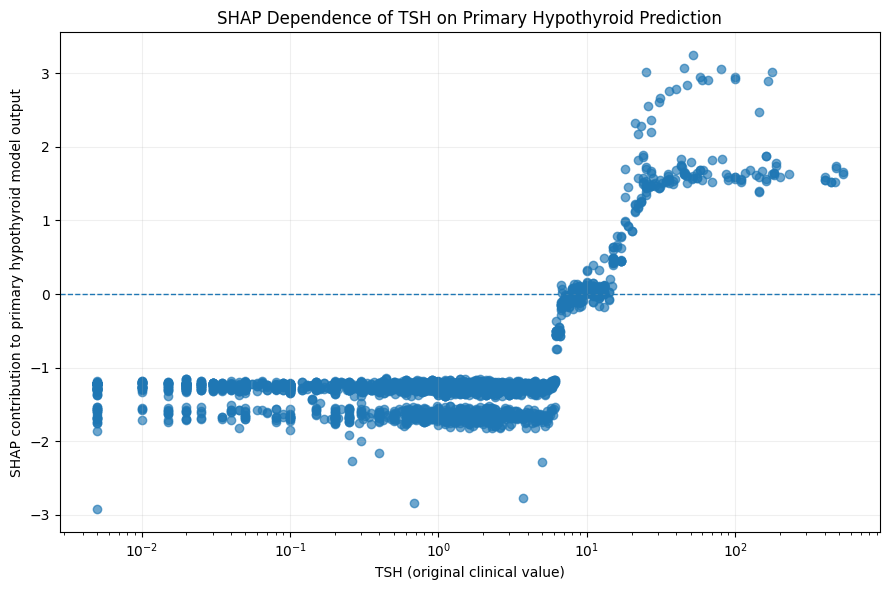

In [24]:
import matplotlib.pyplot as plt
import numpy as np

print("\n" + "=" * 72)
print("FIGURE 6 — TSH / PRIMARY HYPOTHYROID")
print("=" * 72)

# Get processed feature names from the fitted preprocessor
feature_names = preprocessor.get_feature_names_out()

tsh_idx = list(feature_names).index("num__TSH")

# Select primary hypothyroid class
class_idx = list(label_encoder.classes_).index(
    "primary hypothyroid"
)

# Native XGBoost SHAP contributions
tsh_shap = contributions[:, class_idx, tsh_idx]

# Original clinical TSH values
tsh_values = X_test["TSH"].values

# Keep valid positive TSH values for logarithmic axis
valid = np.isfinite(tsh_values) & (tsh_values > 0)

tsh_values = tsh_values[valid]
tsh_shap = tsh_shap[valid]

# Figure 6 — older format
plt.figure(figsize=(9, 6))

plt.scatter(
    tsh_values,
    tsh_shap,
    alpha=0.65
)

plt.axhline(0, linestyle="--", linewidth=1)

plt.xlabel("TSH (original clinical value)")
plt.ylabel("SHAP contribution to primary hypothyroid model output")

plt.title(
    "SHAP Dependence of TSH on Primary Hypothyroid Prediction"
)

plt.xscale("log")

plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    "Figure_6_TSH_Primary_Hypothyroid_Dependence.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

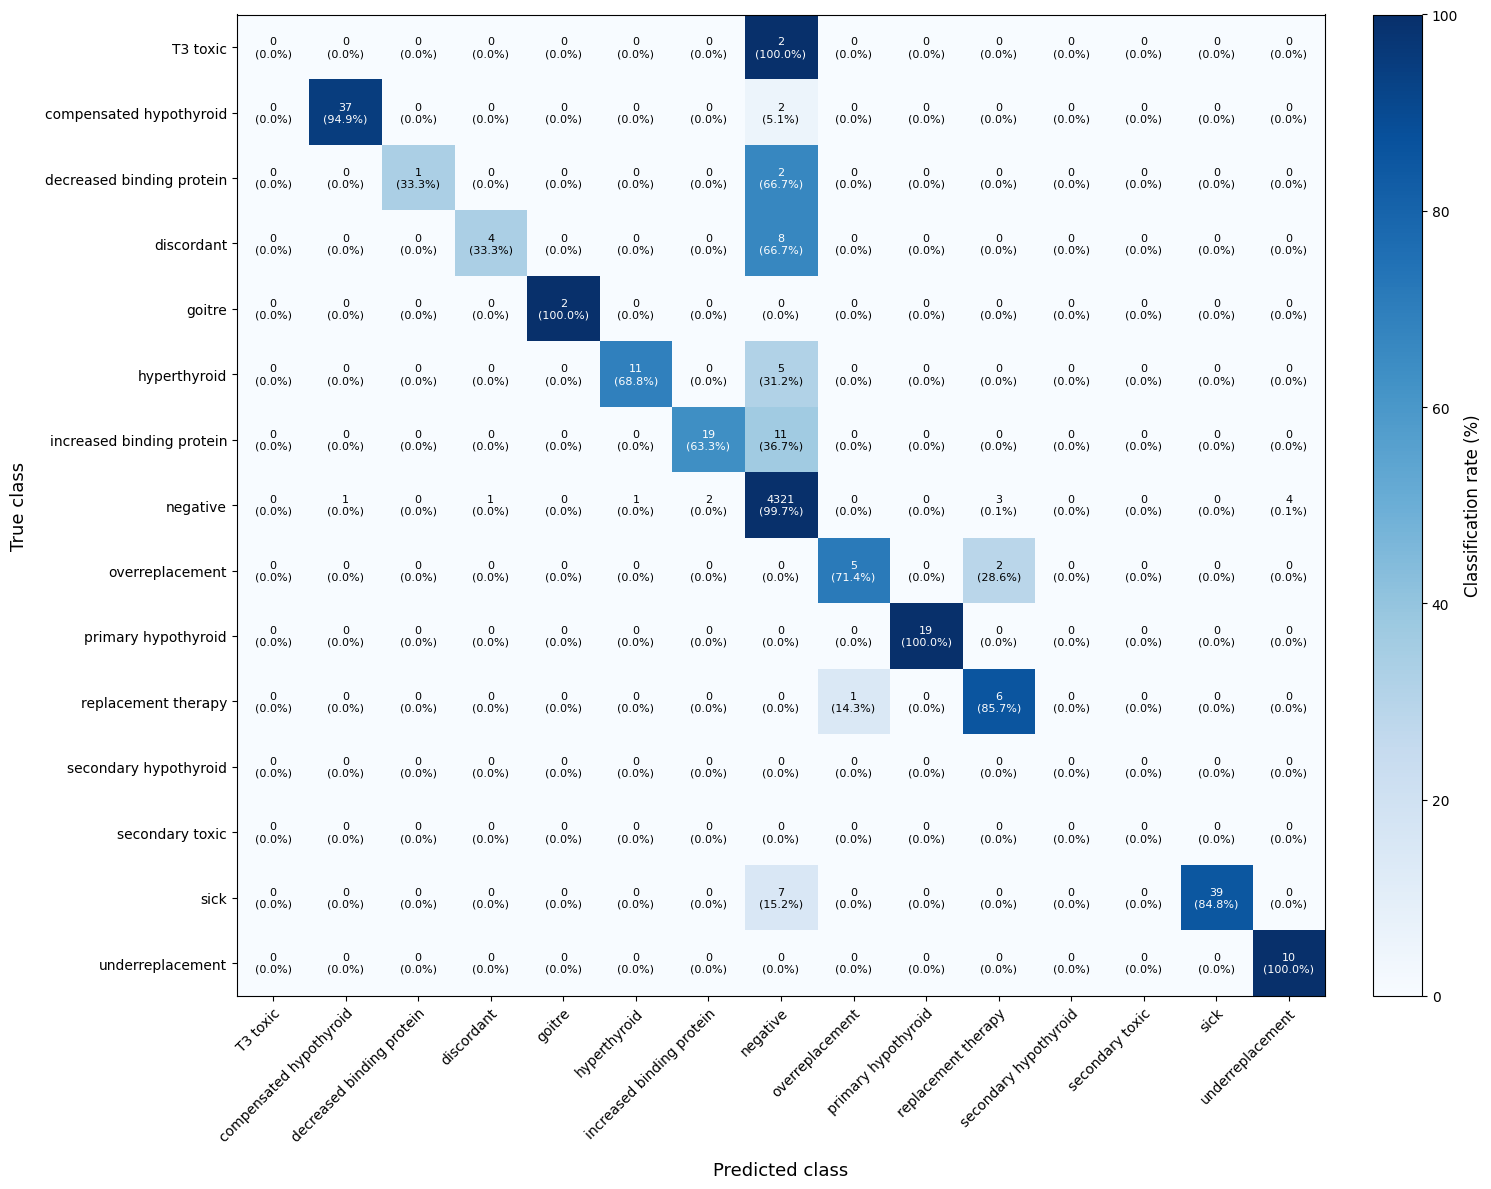

Updated confusion matrix saved:
/workspace/MB Research Experiments/Objective-2/Refined objective 2/2nd Version/Figure_10_Independent_Holdout_Confusion_Matrix.png
Matrix shape: (15, 15)
Total observations: 4526

Per-class observations:
T3 toxic: 2
compensated hypothyroid: 39
decreased binding protein: 3
discordant: 12
goitre: 2
hyperthyroid: 16
increased binding protein: 30
negative: 4333
overreplacement: 7
primary hypothyroid: 19
replacement therapy: 7
secondary hypothyroid: 0
secondary toxic: 0
sick: 46
underreplacement: 10


In [26]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

# ============================================================
# 1. File paths
# ============================================================
csv_path = Path("3Z_E2_independent_holdout_confusion_matrix.csv")

output_path = Path(
    "Figure_10_Independent_Holdout_Confusion_Matrix.png"
)

output_path.parent.mkdir(parents=True, exist_ok=True)

# ============================================================
# 2. Read confusion matrix
# ============================================================
cm_df = pd.read_csv(csv_path, index_col=0)

cm = (
    cm_df.apply(pd.to_numeric, errors="coerce")
    .fillna(0)
    .astype(int)
    .values
)

class_names = list(cm_df.index)

# ============================================================
# 3. Normalize by true class (row-wise percentages)
# ============================================================
row_totals = cm.sum(axis=1, keepdims=True)

cm_percent = np.divide(
    cm * 100,
    row_totals,
    out=np.zeros_like(cm, dtype=float),
    where=row_totals != 0
)

# ============================================================
# 4. Create figure — Light blue color scheme
# ============================================================
fig, ax = plt.subplots(figsize=(15, 12))

im = ax.imshow(
    cm_percent,
    interpolation="nearest",
    aspect="auto",
    cmap="Blues",       # Light blue to dark blue
    vmin=0,
    vmax=100
)

# Colorbar
cbar = fig.colorbar(
    im,
    ax=ax,
    fraction=0.046,
    pad=0.04
)

cbar.set_label(
    "Classification rate (%)",
    fontsize=12
)

cbar.set_ticks([0, 20, 40, 60, 80, 100])

# ============================================================
# 5. Annotate cells with count and percentage
# ============================================================
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):

        count = cm[i, j]
        percentage = cm_percent[i, j]

        # Readable text against light/dark blue cells
        text_color = "white" if percentage >= 50 else "black"

        ax.text(
            j,
            i,
            f"{count}\n({percentage:.1f}%)",
            ha="center",
            va="center",
            fontsize=8,
            color=text_color
        )

# ============================================================
# 6. Axis labels
# ============================================================
ax.set_xticks(np.arange(len(class_names)))
ax.set_yticks(np.arange(len(class_names)))

ax.set_xticklabels(
    class_names,
    rotation=45,
    ha="right",
    rotation_mode="anchor",
    fontsize=10
)

ax.set_yticklabels(
    class_names,
    fontsize=10
)

ax.set_xlabel(
    "Predicted class",
    fontsize=13,
    labelpad=12
)

ax.set_ylabel(
    "True class",
    fontsize=13,
    labelpad=12
)

# No title — manuscript caption provides context

# ============================================================
# 7. Improve layout
# ============================================================
ax.set_xlim(-0.5, len(class_names) - 0.5)
ax.set_ylim(len(class_names) - 0.5, -0.5)

plt.tight_layout()

# ============================================================
# 8. Save publication-quality figure
# ============================================================
fig.savefig(
    output_path,
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.15
)

plt.show()

# ============================================================
# 9. Summary
# ============================================================
print("Updated confusion matrix saved:")
print(output_path.resolve())

print("Matrix shape:", cm.shape)
print("Total observations:", cm.sum())

print("\nPer-class observations:")
for name, total in zip(class_names, row_totals.flatten()):
    print(f"{name}: {total}")


FIGURE 6 — TSH / PRIMARY HYPOTHYROID


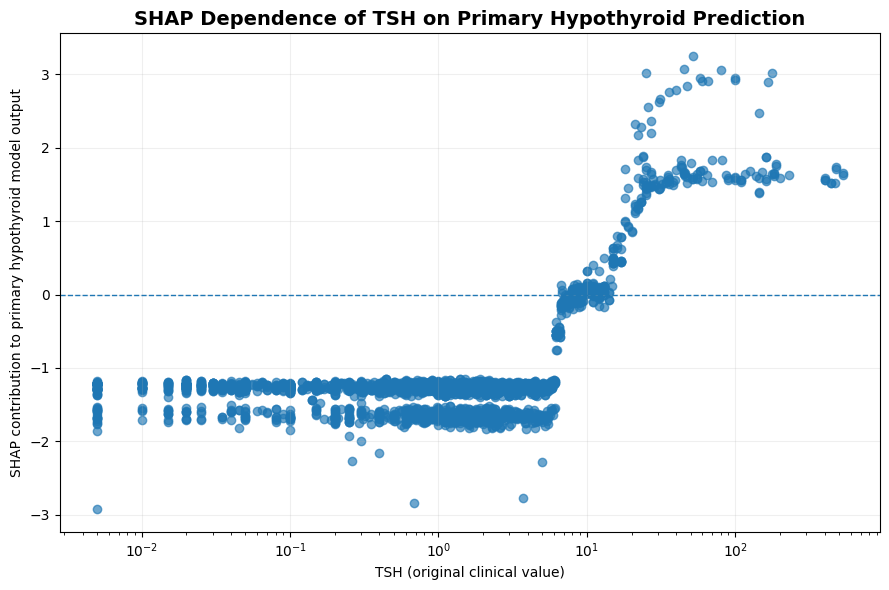

In [27]:
import matplotlib.pyplot as plt
import numpy as np

print("\n" + "=" * 72)
print("FIGURE 6 — TSH / PRIMARY HYPOTHYROID")
print("=" * 72)

# Get processed feature names from the fitted preprocessor
feature_names = preprocessor.get_feature_names_out()

tsh_idx = list(feature_names).index("num__TSH")

# Select primary hypothyroid class
class_idx = list(label_encoder.classes_).index(
    "primary hypothyroid"
)

# Native XGBoost SHAP contributions
tsh_shap = contributions[:, class_idx, tsh_idx]

# Original clinical TSH values
tsh_values = X_test["TSH"].values

# Keep valid positive TSH values for logarithmic axis
valid = np.isfinite(tsh_values) & (tsh_values > 0)

tsh_values = tsh_values[valid]
tsh_shap = tsh_shap[valid]

# Figure 6 — older format
plt.figure(figsize=(9, 6))

plt.scatter(
    tsh_values,
    tsh_shap,
    alpha=0.65
)

plt.axhline(0, linestyle="--", linewidth=1)

plt.xlabel("TSH (original clinical value)")
plt.ylabel("SHAP contribution to primary hypothyroid model output")

plt.title(
    "SHAP Dependence of TSH on Primary Hypothyroid Prediction",
    fontsize=14,
    fontweight="bold"
)

plt.xscale("log")

plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    "Figure_6_TSH_Primary_Hypothyroid_Dependence.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()